# **Import Libraries**

In [3]:
# import modules

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

from sklearn.preprocessing import RobustScaler
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor

print("All done!")

All done!


# **Initial Look on The Data**

In [7]:
# create dataframe

# to display all
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", None)

df = pd.read_csv("bank_transactions_data_2.csv")

print("Successfully created!")


Successfully created!


In [8]:
# get df metadata
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2512 entries, 0 to 2511
Data columns (total 16 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   TransactionID            2512 non-null   str    
 1   AccountID                2512 non-null   str    
 2   TransactionAmount        2512 non-null   float64
 3   TransactionDate          2512 non-null   str    
 4   TransactionType          2512 non-null   str    
 5   Location                 2512 non-null   str    
 6   DeviceID                 2512 non-null   str    
 7   IP Address               2512 non-null   str    
 8   MerchantID               2512 non-null   str    
 9   Channel                  2512 non-null   str    
 10  CustomerAge              2512 non-null   int64  
 11  CustomerOccupation       2512 non-null   str    
 12  TransactionDuration      2512 non-null   int64  
 13  LoginAttempts            2512 non-null   int64  
 14  AccountBalance           2512 non-n

In [9]:
# first 10 rows
df.head(10)

,TransactionID,AccountID,TransactionAmount,TransactionDate,TransactionType,Location,DeviceID,IP Address,MerchantID,Channel,CustomerAge,CustomerOccupation,TransactionDuration,LoginAttempts,AccountBalance,PreviousTransactionDate
0,TX000001,AC00128,14.09,2023-04-11 16:29:14,Debit,San Diego,D000380,162.198.218.92,M015,ATM,70,Doctor,81,1,5112.21,2024-11-04 08:08:08
1,TX000002,AC00455,376.24,2023-06-27 16:44:19,Debit,Houston,D000051,13.149.61.4,M052,ATM,68,Doctor,141,1,13758.91,2024-11-04 08:09:35
2,TX000003,AC00019,126.29,2023-07-10 18:16:08,Debit,Mesa,D000235,215.97.143.157,M009,Online,19,Student,56,1,1122.35,2024-11-04 08:07:04
3,TX000004,AC00070,184.50,2023-05-05 16:32:11,Debit,Raleigh,D000187,200.13.225.150,M002,Online,26,Student,25,1,8569.06,2024-11-04 08:09:06
4,TX000005,AC00411,13.45,2023-10-16 17:51:24,Credit,Atlanta,D000308,65.164.3.100,M091,Online,26,Student,198,1,7429.40,2024-11-04 08:06:39
5,TX000006,AC00393,92.15,2023-04-03 17:15:01,Debit,Oklahoma City,D000579,117.67.192.211,M054,ATM,18,Student,172,1,781.68,2024-11-04 08:06:36
6,TX000007,AC00199,7.08,2023-02-15 16:36:48,Credit,Seattle,D000241,140.212.253.222,M019,ATM,37,Doctor,139,1,13316.71,2024-11-04 08:10:09
7,TX000008,AC00069,171.42,2023-05-08 17:47:59,Credit,Indianapolis,D000500,92.214.76.157,M020,Branch,67,Retired,291,1,2796.24,2024-11-04 08:10:55
8,TX000009,AC00135,106.23,2023-03-21 16:59:46,Credit,Detroit,D000690,24.148.92.177,M035,Branch,51,Engineer,86,1,9095.14,2024-11-04 08:11:14
9,TX000010,AC00385,815.96,2023-03-31 16:06:57,Debit,Nashville,D000199,32.169.88.41,M007,ATM,55,Doctor,120,1,1021.88,2024-11-04 08:06:32


In [10]:
# last 10 rows
df.tail(10)

,TransactionID,AccountID,TransactionAmount,TransactionDate,TransactionType,Location,DeviceID,IP Address,MerchantID,Channel,CustomerAge,CustomerOccupation,TransactionDuration,LoginAttempts,AccountBalance,PreviousTransactionDate
2502,TX002503,AC00069,603.54,2023-04-21 16:22:38,Debit,Albuquerque,D000321,112.86.148.212,M029,Online,44,Doctor,26,1,10517.47,2024-11-04 08:08:08
2503,TX002504,AC00427,270.25,2023-11-06 16:56:41,Debit,Tucson,D000224,147.114.91.132,M065,ATM,31,Engineer,42,1,5414.97,2024-11-04 08:10:48
2504,TX002505,AC00047,123.38,2024-01-01 17:21:56,Debit,Sacramento,D000219,163.129.70.210,M049,Online,59,Doctor,40,1,13542.41,2024-11-04 08:10:53
2505,TX002506,AC00377,577.12,2023-01-27 17:38:07,Debit,Virginia Beach,D000110,120.16.186.17,M075,ATM,39,Engineer,69,1,5265.88,2024-11-04 08:10:50
2506,TX002507,AC00258,92.24,2023-04-13 17:45:33,Debit,Philadelphia,D000531,189.183.50.147,M076,Branch,60,Engineer,93,1,6937.48,2024-11-04 08:09:06
2507,TX002508,AC00297,856.21,2023-04-26 17:09:36,Credit,Colorado Springs,D000625,21.157.41.17,M072,Branch,33,Doctor,109,1,12690.79,2024-11-04 08:11:29
2508,TX002509,AC00322,251.54,2023-03-22 17:36:48,Debit,Tucson,D000410,49.174.157.140,M029,Branch,48,Doctor,177,1,254.75,2024-11-04 08:11:42
2509,TX002510,AC00095,28.63,2023-08-21 17:08:50,Debit,San Diego,D000095,58.1.27.124,M087,Branch,56,Retired,146,1,3382.91,2024-11-04 08:08:39
2510,TX002511,AC00118,185.97,2023-02-24 16:24:46,Debit,Denver,D000634,21.190.11.223,M041,Online,23,Student,19,1,1776.91,2024-11-04 08:12:22
2511,TX002512,AC00009,243.08,2023-02-14 16:21:23,Credit,Jacksonville,D000215,59.127.135.25,M041,Online,24,Student,93,1,131.25,2024-11-04 08:07:49


In [23]:
# descriptive statistics for numerical
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
TransactionAmount,2512.0,297.59,291.95,0.26,81.89,211.14,414.53,1919.11
CustomerAge,2512.0,44.67,17.79,18.00,27.00,45.00,59.00,80.00
TransactionDuration,2512.0,119.64,69.96,10.00,63.00,112.50,161.00,300.00
LoginAttempts,2512.0,1.12,0.60,1.00,1.00,1.00,1.00,5.00
AccountBalance,2512.0,5114.30,3900.94,101.25,1504.37,4735.51,7678.82,14977.99


In [21]:
# descriptive statistics for categorical
df.describe(include=['object', 'str']).T

,count,unique,top,freq
TransactionID,2512,2512,TX000001,1
AccountID,2512,495,AC00202,12
TransactionDate,2512,2512,2023-04-11 16:29:14,1
TransactionType,2512,2,Debit,1944
Location,2512,43,Fort Worth,70
DeviceID,2512,681,D000142,9
IP Address,2512,592,200.136.146.93,13
MerchantID,2512,100,M026,45
Channel,2512,3,Branch,868
CustomerOccupation,2512,4,Student,657


In [22]:
# count unique values column
df.nunique().sort_values(ascending=False)

TransactionID              2512
TransactionDate            2512
AccountBalance             2510
TransactionAmount          2455
DeviceID                    681
IP Address                  592
AccountID                   495
PreviousTransactionDate     360
TransactionDuration         288
MerchantID                  100
CustomerAge                  63
Location                     43
LoginAttempts                 5
CustomerOccupation            4
Channel                       3
TransactionType               2
dtype: int64

# **Data Cleaning**

In [24]:
# to prevent alteration
df_c = df.copy()

df_c.info()

<class 'pandas.DataFrame'>
RangeIndex: 2512 entries, 0 to 2511
Data columns (total 16 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   TransactionID            2512 non-null   str    
 1   AccountID                2512 non-null   str    
 2   TransactionAmount        2512 non-null   float64
 3   TransactionDate          2512 non-null   str    
 4   TransactionType          2512 non-null   str    
 5   Location                 2512 non-null   str    
 6   DeviceID                 2512 non-null   str    
 7   IP Address               2512 non-null   str    
 8   MerchantID               2512 non-null   str    
 9   Channel                  2512 non-null   str    
 10  CustomerAge              2512 non-null   int64  
 11  CustomerOccupation       2512 non-null   str    
 12  TransactionDuration      2512 non-null   int64  
 13  LoginAttempts            2512 non-null   int64  
 14  AccountBalance           2512 non-n

In [25]:
# rename columns
df_c.rename(columns={'TransactionID':'transaction_id', 'AccountID':'account_id', 'TransactionAmount':'transaction_amount', 'TransactionDate':'transaction_date',
       'TransactionType':'transaction_type', 'Location':'location', 'DeviceID':'device_id', 'IP Address':'ip_address', 'MerchantID':'merchant_id',
       'Channel':'channel', 'CustomerAge':'customer_age', 'CustomerOccupation':'customer_occupation', 'TransactionDuration':'transaction_seconds_duration',
       'LoginAttempts':'login_attempts', 'AccountBalance':'account_balance', 'PreviousTransactionDate':'previous_transaction_date'}, inplace=True)

df_c.columns

Index(['transaction_id', 'account_id', 'transaction_amount',
       'transaction_date', 'transaction_type', 'location', 'device_id',
       'ip_address', 'merchant_id', 'channel', 'customer_age',
       'customer_occupation', 'transaction_seconds_duration', 'login_attempts',
       'account_balance', 'previous_transaction_date'],
      dtype='str')

In [26]:
# inspect columns for standardization
for col in df_c.select_dtypes(include='object').columns:
  print(f"{col}")
  print(df_c[col].unique())
  print()

transaction_id
<StringArray>
['TX000001', 'TX000002', 'TX000003', 'TX000004', 'TX000005', 'TX000006',
 'TX000007', 'TX000008', 'TX000009', 'TX000010',
 ...
 'TX002503', 'TX002504', 'TX002505', 'TX002506', 'TX002507', 'TX002508',
 'TX002509', 'TX002510', 'TX002511', 'TX002512']
Length: 2512, dtype: str

account_id
<StringArray>
['AC00128', 'AC00455', 'AC00019', 'AC00070', 'AC00411', 'AC00393', 'AC00199',
 'AC00069', 'AC00135', 'AC00385',
 ...
 'AC00088', 'AC00388', 'AC00008', 'AC00252', 'AC00186', 'AC00472', 'AC00476',
 'AC00038', 'AC00238', 'AC00308']
Length: 495, dtype: str

transaction_date
<StringArray>
['2023-04-11 16:29:14', '2023-06-27 16:44:19', '2023-07-10 18:16:08',
 '2023-05-05 16:32:11', '2023-10-16 17:51:24', '2023-04-03 17:15:01',
 '2023-02-15 16:36:48', '2023-05-08 17:47:59', '2023-03-21 16:59:46',
 '2023-03-31 16:06:57',
 ...
 '2023-04-21 16:22:38', '2023-11-06 16:56:41', '2024-01-01 17:21:56',
 '2023-01-27 17:38:07', '2023-04-13 17:45:33', '2023-04-26 17:09:36',
 '2023-

C:\Users\admin\AppData\Local\Temp\ipykernel_11988\1614835380.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in df_c.select_dtypes(include='object').columns:


In [27]:
# check missing data
for col in df_c.columns:
  pct_missing = np.mean(df_c[col].isnull())
  print('{} - {}%'.format(col, pct_missing))

transaction_id - 0.0%
account_id - 0.0%
transaction_amount - 0.0%
transaction_date - 0.0%
transaction_type - 0.0%
location - 0.0%
device_id - 0.0%
ip_address - 0.0%
merchant_id - 0.0%
channel - 0.0%
customer_age - 0.0%
customer_occupation - 0.0%
transaction_seconds_duration - 0.0%
login_attempts - 0.0%
account_balance - 0.0%
previous_transaction_date - 0.0%


In [28]:
# check duplicated data
dup_data = df_c.duplicated().sum()
any_dup = df_c.duplicated().any()


print("Result: ")
print("---"*5)
print(f"Duplicate Status: {any_dup}")
print(f"Total Duplicated Values: {dup_data}")

Result: 
---------------
Duplicate Status: False
Total Duplicated Values: 0


# **EDA: Transaction Behavior**

This section explores the distribution of transaction-related variables using descriptive statistics and visualizations.

Business Questions
- What are the typical transaction amounts?
- Which transaction type (Credit or Debit) occurs most frequently?
- Which transaction channels are most commonly used (Online, ATM, or Branch)?

#### **1. What are the typical transaction amounts?**

#### Objective:

To examine the distribution and central tendency of transaction amounts and establish a baseline of typical customer spending behavior. This analysis also identifies unusually large transactions that may indicate anomalous activity and require further investigation.

In [29]:
df_c.head()

,transaction_id,account_id,transaction_amount,transaction_date,transaction_type,location,device_id,ip_address,merchant_id,channel,customer_age,customer_occupation,transaction_seconds_duration,login_attempts,account_balance,previous_transaction_date
0,TX000001,AC00128,14.09,2023-04-11 16:29:14,Debit,San Diego,D000380,162.198.218.92,M015,ATM,70,Doctor,81,1,5112.21,2024-11-04 08:08:08
1,TX000002,AC00455,376.24,2023-06-27 16:44:19,Debit,Houston,D000051,13.149.61.4,M052,ATM,68,Doctor,141,1,13758.91,2024-11-04 08:09:35
2,TX000003,AC00019,126.29,2023-07-10 18:16:08,Debit,Mesa,D000235,215.97.143.157,M009,Online,19,Student,56,1,1122.35,2024-11-04 08:07:04
3,TX000004,AC00070,184.50,2023-05-05 16:32:11,Debit,Raleigh,D000187,200.13.225.150,M002,Online,26,Student,25,1,8569.06,2024-11-04 08:09:06
4,TX000005,AC00411,13.45,2023-10-16 17:51:24,Credit,Atlanta,D000308,65.164.3.100,M091,Online,26,Student,198,1,7429.40,2024-11-04 08:06:39


In [30]:
df_c['transaction_amount'].describe().T

count    2512.000000
mean      297.593778
std       291.946243
min         0.260000
25%        81.885000
50%       211.140000
75%       414.527500
max      1919.110000
Name: transaction_amount, dtype: float64

In [31]:
median_trans_amount = df_c['transaction_amount'].median()

print(f"Transaction Amount Median: {median_trans_amount}")

Transaction Amount Median: 211.14


#### **Findings:**

- The distribution of transaction amounts is positively (right) skewed, as indicated by the mean (297.59) being higher than the median (211.14). This suggests that a relatively small number of high-value transactions increase the average transaction amount.
Most transactions are concentrated at lower values, with the majority of transactions occurring below 500.
Transaction frequency decreases as transaction amounts increase, resulting in a long right tail that extends to approximately 1,900.
The long right tail indicates that high-value transactions are relatively uncommon compared to low- and medium-value transactions.


#### **Business Interpretation:**

- The transaction distribution suggests that customers typically perform low- to medium-value transactions. High-value transactions occur less frequently and represent deviations from normal spending behavior. These transactions should be examined further during anomaly detection, as unusually large transaction amounts may indicate suspicious financial activity.

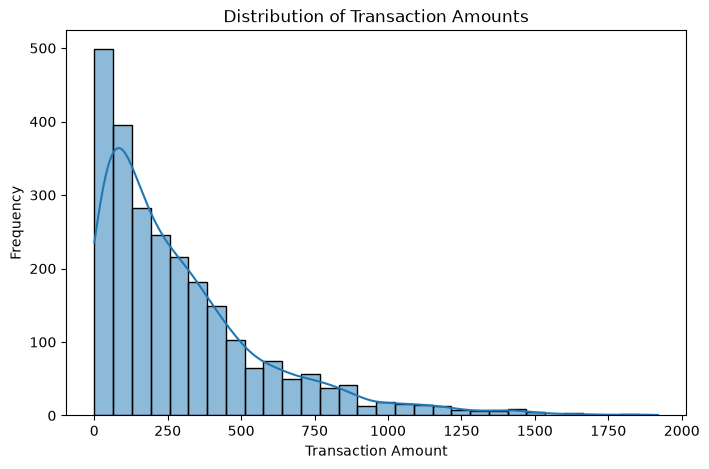

In [32]:
# histogram for distribution of transaction amounts

plt.figure(figsize=(8,5))

sns.histplot(
    data=df_c,
    x='transaction_amount',
    bins=30,
    kde=True
)

plt.title("Distribution of Transaction Amounts")
plt.xlabel('Transaction Amount')
plt.ylabel('Frequency')

plt.show()


#### **Findings:**

The boxplot reveals several observations beyond the upper whisker, indicating the presence of potential outliers.
Using the IQR method, the upper limit for transaction amounts is 913.49. Transactions exceeding this threshold are considered statistical outliers.
Transaction amounts extend to approximately 1,900, indicating the presence of several unusually large transactions.

#### **Business Interpretation:**

Although transactions above 913.49 are considered statistical outliers, they were retained in the dataset because the objective of this project is anomaly detection. These high-value transactions may represent unusual customer behavior and therefore serve as important candidates for further fraud investigation rather than being removed during preprocessing.

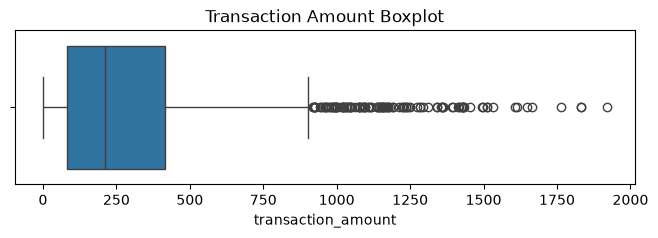

In [33]:
# transaction amount boxplot
plt.figure(figsize=(8,2))

sns.boxplot(
    data=df_c,
    x='transaction_amount'
)

plt.title('Transaction Amount Boxplot')

plt.show()

In [34]:
# to find the accepted limit in the box plot
# 1.5 = iqr rule that is used to define the boundaries for identifying outliers
q1 = df_c["transaction_amount"].quantile(0.25)
q3 = df_c["transaction_amount"].quantile(0.75)

iqr = q3 - q1

lower_limit = q1 - 1.5 * iqr
upper_limit = q3 + 1.5 * iqr

print(f"Transaction Amount Upper Limit: {upper_limit:.2f}")
print(f"Transaction Amount Lower Limit: {lower_limit:.2f}")

Transaction Amount Upper Limit: 913.49
Transaction Amount Lower Limit: -417.08


In [39]:
# to identify outlier data points
df_c[df_c['transaction_amount'] > upper_limit]

# the results are the outlier data points

,transaction_id,account_id,transaction_amount,transaction_date,transaction_type,location,device_id,ip_address,merchant_id,channel,customer_age,customer_occupation,transaction_seconds_duration,login_attempts,account_balance,previous_transaction_date
74,TX000075,AC00265,1212.51,2023-10-04 16:36:29,Debit,Indianapolis,D000231,193.83.0.183,M036,Branch,20,Student,24,1,605.95,2024-11-04 08:06:51
82,TX000083,AC00236,922.55,2023-01-23 16:32:48,Debit,Detroit,D000206,21.97.154.92,M004,ATM,63,Retired,87,1,4715.84,2024-11-04 08:11:07
85,TX000086,AC00098,1340.19,2023-09-29 17:22:10,Credit,Austin,D000574,165.114.224.47,M012,Online,54,Engineer,30,1,8654.28,2024-11-04 08:06:53
110,TX000111,AC00068,1045.22,2023-11-22 16:13:39,Debit,Columbus,D000400,77.7.223.184,M077,ATM,53,Retired,73,1,1829.90,2024-11-04 08:07:35
129,TX000130,AC00320,1036.66,2023-07-11 16:39:53,Debit,San Antonio,D000015,53.218.177.171,M062,Branch,58,Doctor,144,1,5541.57,2024-11-04 08:09:24
138,TX000139,AC00405,997.43,2023-11-22 16:07:19,Debit,Seattle,D000661,100.4.40.132,M067,Online,69,Doctor,118,1,6810.05,2024-11-04 08:08:25
141,TX000142,AC00114,1049.92,2023-10-23 16:50:33,Debit,Detroit,D000522,121.67.144.20,M052,ATM,80,Retired,21,1,2037.85,2024-11-04 08:10:34
146,TX000147,AC00385,973.39,2023-08-30 17:23:20,Debit,Sacramento,D000292,202.194.199.70,M026,Branch,77,Retired,296,1,2042.22,2024-11-04 08:11:44
176,TX000177,AC00363,1362.55,2023-02-10 18:07:07,Debit,El Paso,D000213,93.52.44.101,M001,ATM,29,Engineer,106,1,2429.68,2024-11-04 08:11:05
186,TX000187,AC00099,1041.88,2023-09-06 16:44:02,Debit,Jacksonville,D000208,32.240.176.64,M032,Online,78,Retired,57,1,5726.20,2024-11-04 08:06:44


#### **2. Which transaction types (Credit or Debit) occur most frequently?**

#### Objective:

To examine the distribution of transaction types and identify the predominant mode of customer transactions. Understanding the frequency of credit and debit transactions establishes a baseline of normal transaction behavior and provides context for subsequent behavioral analysis.

In [40]:
# frequency count
df_c['transaction_type'].value_counts()

transaction_type
Debit     1944
Credit     568
Name: count, dtype: int64

In [41]:
# percentage distribution
(
    df_c['transaction_type']
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

transaction_type
Debit     77.39
Credit    22.61
Name: proportion, dtype: float64

In [44]:
# descriptive statistics
df_c['transaction_type'].describe()

count      2512
unique        2
top       Debit
freq       1944
Name: transaction_type, dtype: object

#### **Findings:**

A total of 2,512 transactions were recorded in the dataset. Among these, Debit transactions account for 1,944 transactions (77.39%), while Credit transactions account for 568 transactions (22.61%). This indicates that debit transactions are substantially more common than credit transactions.

#### **Business Interpretation:**

The predominance of debit transactions suggests that customers primarily use their accounts for everyday spending and withdrawals. This distribution establishes a baseline of normal transaction behavior, which is valuable for anomaly detection. Transactions involving the less common credit transaction type may warrant closer examination when combined with other unusual characteristics, such as unusually large transaction amounts, multiple login attempts, or unfamiliar devices.

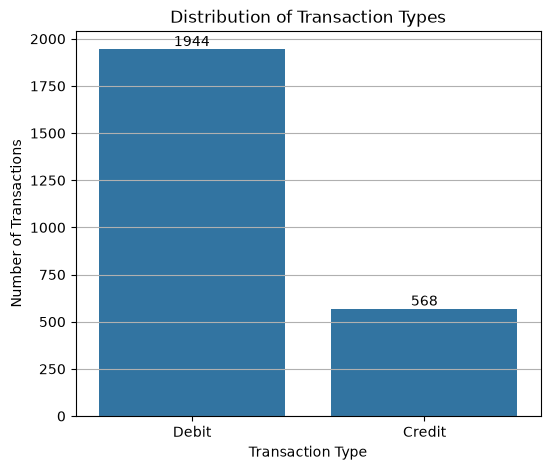

In [42]:
plt.figure(figsize=(6,5))

ax = sns.countplot(
    data=df_c,
    x='transaction_type',
    order=df_c['transaction_type'].value_counts().index
)

for container in ax.containers:
    ax.bar_label(container)

plt.title('Distribution of Transaction Types')
plt.xlabel('Transaction Type')
plt.ylabel('Number of Transactions')

plt.grid(axis='y')
plt.show()

#### **3. Which channels are most commonly used (Online, ATM, Branch)?**

#### Objective:

Determine the most frequently used transaction channel to understand customer banking preferences and establish a baseline for transaction behavior.

In [46]:
# descriptive stats
df_c['channel'].value_counts()

channel
Branch    868
ATM       833
Online    811
Name: count, dtype: int64

In [47]:
# percentage distribution
(
    df_c['channel']
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

channel
Branch    34.55
ATM       33.16
Online    32.29
Name: proportion, dtype: float64

#### **Findings:**

A total of 2,512 transactions were conducted across three transaction channels. Branch recorded the highest number of transactions with 868 (34.55%), followed by ATM with 833 (33.16%), and Online with 811 (32.29%). The small differences in transaction counts indicate that customers use all three channels at relatively similar frequencies.

#### **Business Interpretation:**

The relatively balanced distribution of transaction channels suggests that customers do not rely heavily on a single banking channel. This establishes a baseline of normal channel usage, allowing future anomaly detection models to identify transactions that deviate from a customer's typical transaction channel when combined with other suspicious indicators, such as unusually large transaction amounts or multiple login attempts.

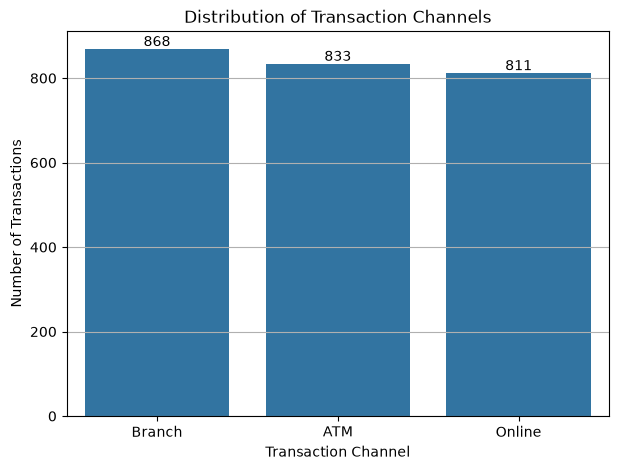

In [48]:
plt.figure(figsize=(7,5))

ax = sns.countplot(
    data=df_c,
    x='channel',
    order=df_c['channel'].value_counts().index
)

for container in ax.containers:
  ax.bar_label(container)

plt.title('Distribution of Transaction Channels')
plt.xlabel('Transaction Channel')
plt.ylabel('Number of Transactions')

plt.grid(axis='y')
plt.show()

# **EDA: Customer Behavior**

This section analyzes customer transaction behavior and answer the following business questions:

- How often do customers transact?
- Do customers usually transact from one location or multiple locations?
- How many devices are associated with each account?

#### **1. How often do customers transact?**

#### Objective:

To examine the frequency of transactions made by each customer account and identify typical transaction behavior. Understanding how often customers transact establishes a baseline of normal activity and helps identify unusually active accounts that may warrant further investigation during anomaly detection.


In [49]:
# calculate the number of ransactions per customer

transactions_per_customer = (
    df_c.groupby('account_id')
    .size()
    .sort_values(ascending=False)
)

transactions_per_customer

account_id
AC00460    12
AC00363    12
AC00362    12
AC00202    12
AC00480    11
AC00257    11
AC00225    11
AC00456    11
AC00304    11
AC00267    10
AC00063    10
AC00219    10
AC00297    10
AC00035     9
AC00014     9
AC00032     9
AC00453     9
AC00130     9
AC00030     9
AC00329     9
AC00265     9
AC00427     9
AC00241     9
AC00279     9
AC00339     9
AC00439     9
AC00322     9
AC00131     9
AC00004     9
AC00275     9
AC00020     9
AC00005     9
AC00090     9
AC00373     9
AC00345     9
AC00177     9
AC00054     9
AC00442     9
AC00093     9
AC00242     9
AC00087     9
AC00261     8
AC00475     8
AC00393     8
AC00438     8
AC00110     8
AC00337     8
AC00176     8
AC00332     8
AC00228     8
AC00272     8
AC00284     8
AC00071     8
AC00092     8
AC00182     8
AC00070     8
AC00396     8
AC00356     8
AC00358     8
AC00386     8
AC00464     8
AC00465     8
AC00144     8
AC00366     8
AC00498     8
AC00021     8
AC00095     8
AC00139     8
AC00136     8
AC00403     8
AC00495  

In [54]:
# summary statistics
transactions_per_customer.describe().T

count    495.000000
mean       5.074747
std        2.294261
min        1.000000
25%        3.000000
50%        5.000000
75%        7.000000
max       12.000000
Name: count, dtype: float64

In [55]:
# check skewness
df_c['account_id'].value_counts().describe().skew()

np.float64(2.8262744067927392)

In [51]:
transactions_per_customer.value_counts().sort_index()

1     24
2     43
3     62
4     81
5     87
6     68
7     58
8     31
9     28
10     4
11     5
12     4
Name: count, dtype: int64


#### **Findings:**

The dataset contains 495 unique customer accounts, with each customer performing an average of 5.07 transactions. Most customers completed between 3 and 7 transactions, indicating relatively consistent transaction activity across accounts. A small number of customers recorded 10 or more transactions, resulting in a positively skewed distribution of transaction frequency.

#### **Business Interpretation:**

The relatively consistent transaction frequency suggests that most customers exhibit similar transaction behavior. While a small number of customers transact more frequently than others, transaction frequency alone is not sufficient to indicate fraudulent activity. Instead, it should be analyzed alongside other behavioral indicators, such as transaction amount, login attempts, transaction channel, device usage, and IP address changes, to identify potentially anomalous transactions.

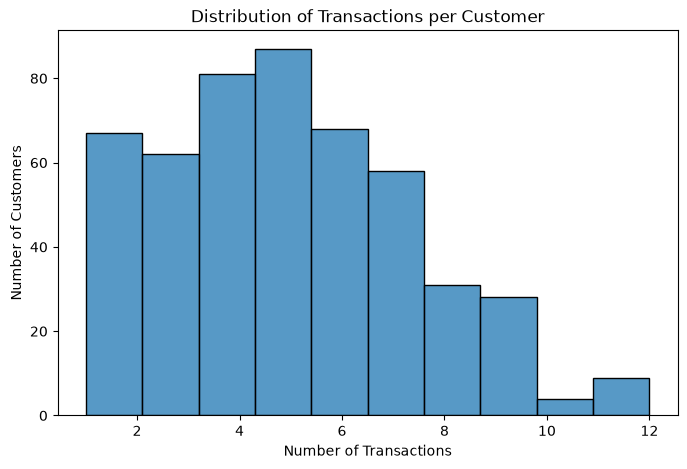

In [53]:
transactions_per_customer = (
    df_c['account_id']
        .value_counts()
)

plt.figure(figsize=(8,5))

sns.histplot(transactions_per_customer, bins=10)

plt.title('Distribution of Transactions per Customer')
plt.xlabel('Number of Transactions')
plt.ylabel('Number of Customers')

plt.show()

In [52]:
# identify the top 10 most active customers

top10_summary = (
    df_c.groupby('account_id')
    .agg(
        Transaction_Count=('account_id', 'size'),
        Total_Amount=('transaction_amount', 'sum'),
        Average_Amount=('transaction_amount', 'mean'),
        Average_Balance=('account_balance', 'mean')
    )
    .sort_values('Transaction_Count', ascending=False)
    .head(10)
)

top10_summary

,Transaction_Count,Total_Amount,Average_Amount,Average_Balance
account_id,,,,
AC00460,12,5570.34,464.195000,4887.100833
AC00363,12,4702.91,391.909167,5502.639167
AC00362,12,2991.32,249.276667,5397.561667
AC00202,12,3722.12,310.176667,3980.296667
AC00480,11,3309.50,300.863636,6048.868182
AC00257,11,3410.02,310.001818,6594.159091
AC00225,11,2926.30,266.027273,4387.590909
AC00456,11,3090.60,280.963636,4777.488182
AC00304,11,3651.80,331.981818,6378.040909


#### **2. Do customers usually transact from one location or multiple locations?**

Objective:

To examine the geographic transaction behavior of customers by determining how many unique locations each customer transacts from. Understanding whether customers typically transact from a single location or multiple locations helps establish normal behavioral patterns and may assist in identifying unusual location changes that warrant further investigation.

In [56]:
# count the number of unique locations per customer

loc_per_customer = (
    df_c.groupby('account_id')['location']
    .nunique()
    .sort_values(ascending=False)
)

loc_per_customer

account_id
AC00363    11
AC00202    11
AC00257    11
AC00267    10
AC00225    10
AC00362    10
AC00480    10
AC00297    10
AC00030     9
AC00304     9
AC00373     9
AC00090     9
AC00442     9
AC00130     9
AC00177     9
AC00456     9
AC00460     9
AC00453     9
AC00005     9
AC00279     9
AC00265     9
AC00219     9
AC00322     9
AC00014     9
AC00004     9
AC00021     8
AC00465     8
AC00345     8
AC00339     8
AC00071     8
AC00329     8
AC00035     8
AC00054     8
AC00356     8
AC00032     8
AC00131     8
AC00020     8
AC00136     8
AC00176     8
AC00144     8
AC00337     8
AC00396     8
AC00403     8
AC00498     8
AC00241     8
AC00095     8
AC00228     8
AC00093     8
AC00087     8
AC00092     8
AC00110     8
AC00063     8
AC00292     7
AC00076     7
AC00291     7
AC00070     7
AC00331     7
AC00332     7
AC00310     7
AC00013     7
AC00495     7
AC00041     7
AC00039     7
AC00475     7
AC00390     7
AC00393     7
AC00394     7
AC00358     7
AC00385     7
AC00398     7
AC00370  

In [57]:
# summary statistics
loc_per_customer.describe()

count    495.000000
mean       4.783838
std        2.115047
min        1.000000
25%        3.000000
50%        5.000000
75%        6.000000
max       11.000000
Name: location, dtype: float64

In [59]:
loc_per_customer.skew()

np.float64(0.31944941022587703)

In [60]:
loc_per_customer.value_counts().sort_index()

location
1     25
2     47
3     74
4     83
5     96
6     63
7     55
8     27
9     17
10     5
11     3
Name: count, dtype: int64

#### **Findings:**

The dataset contains 495 unique customer accounts, with customers transacting from an average of 4.78 unique locations. Most customers conducted transactions across 3 to 6 locations, while only a small number transacted from as many as 10 or 11 unique locations. The distribution of unique transaction locations is approximately symmetric, indicating relatively consistent location usage among customers.

#### **Business Interpretation:**
Customers generally transact from multiple locations rather than a single location, suggesting that multi-location activity is common within this dataset. Therefore, the number of transaction locations alone is unlikely to indicate fraudulent behavior. Instead, unusual location activity should be assessed alongside temporal, device, IP address, and transaction amount information to better identify potentially anomalous transactions.


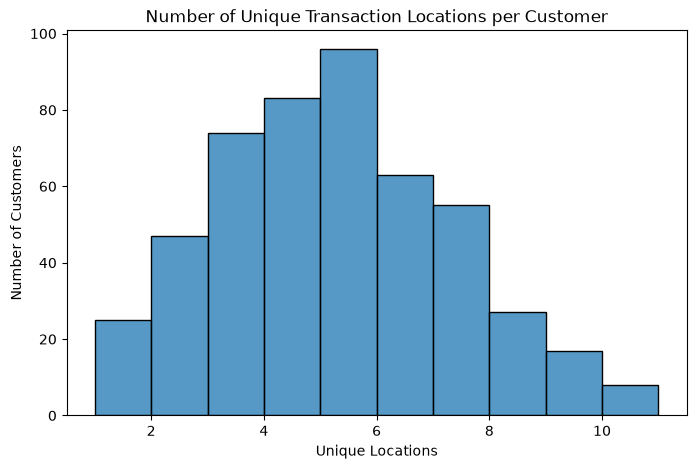

In [58]:
plt.figure(figsize=(8,5))

sns.histplot(
    loc_per_customer,
    bins=10
)

plt.title('Number of Unique Transaction Locations per Customer')
plt.xlabel('Unique Locations')
plt.ylabel('Number of Customers')

plt.show()

#### **Findings:**
For the customer accounts shown, each transaction was performed from a different location, with every customer-location pair recording only one transaction. This indicates that these customers did not repeatedly transact from the same location within the observed sample.

In [61]:
# "How are each customer's transactions distributed across locations?"

customer_loc_counts = (
    df_c.groupby(['account_id', 'location'])
    .size()
    .reset_index(name='Transactions')
)

customer_loc_counts.head(20)

,account_id,location,Transactions
0,AC00001,Atlanta,1
1,AC00001,Denver,1
2,AC00002,Charlotte,1
3,AC00002,Dallas,1
4,AC00002,El Paso,1
5,AC00002,Las Vegas,1
6,AC00002,Los Angeles,1
7,AC00002,Milwaukee,1
8,AC00002,San Diego,1
9,AC00003,Baltimore,1


#### **3. How many devices are associated with each account?**

Objective:

To determine how many unique devices are associated with each customer account and establish a baseline for normal device usage. Understanding device usage patterns helps identify accounts accessed from an unusually large number of devices, which may indicate anomalous or potentially fraudulent activity.

In [62]:
# count unique devices per account
dev_per_customer = (
    df_c.groupby('account_id')['device_id']
    .nunique()
    .sort_values(ascending=False)
)

dev_per_customer

account_id
AC00202    12
AC00362    12
AC00460    12
AC00363    12
AC00257    11
AC00304    11
AC00456    11
AC00225    11
AC00480    10
AC00219    10
AC00297    10
AC00063    10
AC00279     9
AC00090     9
AC00093     9
AC00014     9
AC00054     9
AC00035     9
AC00005     9
AC00004     9
AC00427     9
AC00265     9
AC00267     9
AC00373     9
AC00453     9
AC00130     9
AC00131     9
AC00242     9
AC00087     9
AC00020     9
AC00030     9
AC00032     9
AC00339     9
AC00329     9
AC00439     9
AC00177     9
AC00275     9
AC00322     9
AC00442     9
AC00345     9
AC00356     8
AC00136     8
AC00241     8
AC00272     8
AC00139     8
AC00396     8
AC00095     8
AC00110     8
AC00070     8
AC00261     8
AC00284     8
AC00071     8
AC00092     8
AC00393     8
AC00495     8
AC00475     8
AC00403     8
AC00013     8
AC00021     8
AC00498     8
AC00176     8
AC00228     8
AC00144     8
AC00337     8
AC00464     8
AC00358     8
AC00366     8
AC00438     8
AC00465     8
AC00332     8
AC00182  

In [63]:
# descriptive stats
dev_per_customer.describe()

count    495.000000
mean       5.050505
std        2.277214
min        1.000000
25%        3.000000
50%        5.000000
75%        7.000000
max       12.000000
Name: device_id, dtype: float64

In [64]:
dev_per_customer.skew()

np.float64(0.3815445241409663)

In [65]:
dev_per_customer.median()

np.float64(5.0)

In [67]:
# frequency table
dev_per_customer.value_counts().sort_index()

device_id
1     24
2     43
3     62
4     84
5     86
6     69
7     56
8     31
9     28
10     4
11     4
12     4
Name: count, dtype: int64

#### **Findings:**

The dataset contains 495 unique customer accounts, with each customer associated with an average of 5.05 unique devices. Most customers use between 3 and 7 devices, while only a small number are associated with 10 to 12 devices. The distribution of device usage is approximately symmetric, suggesting relatively consistent device usage across customer accounts.

#### **Business Interpretation:**

Customers in this dataset generally use multiple devices to perform transactions, indicating that multi-device access is common. Therefore, the number of devices alone is unlikely to distinguish fraudulent activity. However, accounts associated with an unusually large number of devices may warrant further investigation when combined with other indicators such as unfamiliar locations, multiple login attempts, high transaction amounts, or unusual transaction timing.

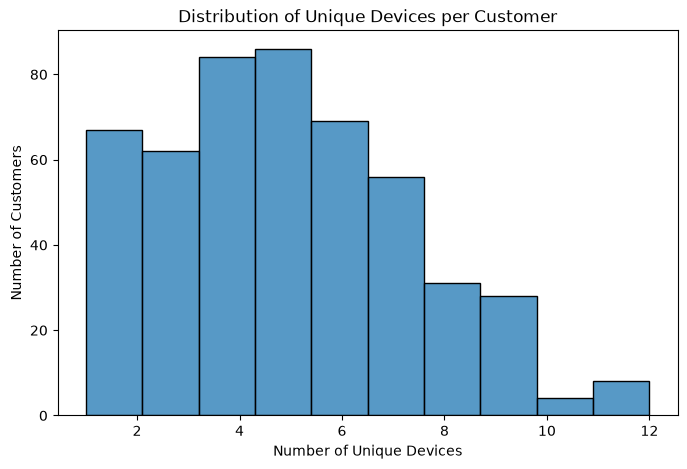

In [66]:
plt.figure(figsize=(8,5))

sns.histplot(
    dev_per_customer,
    bins=10
)

plt.title('Distribution of Unique Devices per Customer')
plt.xlabel('Number of Unique Devices')
plt.ylabel('Number of Customers')

plt.show()

# **EDA: Security Behavior**

To analyze security-related transaction behavior and answer the following business questions:

- Are high login attempts associated with unusual transactions?
- Which channels have the highest average login attempts?
- Which locations generate the highest-value transactions?

#### **1. Are high login attempts associated with unusual transactions?**

Objective:

To determine whether transactions with higher login attempts exhibit characteristics that differ from typical transactions, such as larger transaction amounts or longer transaction durations. This helps assess whether repeated login attempts may be indicative of potentially suspicious activity.

In [68]:
# summary statistics
df_c.groupby('login_attempts')['transaction_amount'].describe()

,count,mean,std,min,25%,50%,75%,max
login_attempts,,,,,,,,
1,2390.0,298.027054,292.775303,0.26,81.1800,211.27,416.2475,1919.11
2,27.0,334.077778,286.937819,53.81,144.0800,278.88,370.4350,1250.94
3,31.0,265.923871,194.163349,11.06,103.9450,280.61,403.3200,705.60
4,32.0,253.762187,316.821964,15.81,75.9100,131.35,317.3675,1531.31
5,32.0,308.961875,296.422817,1.93,119.7875,250.24,435.9425,1192.20


#### **Findings:**

Most transactions (2,390 out of 2,512) were completed after a single login attempt. Transactions requiring multiple login attempts were relatively rare. The average transaction amount and transaction duration varied across login attempt groups, but no consistent trend was observed as login attempts increased.

#### **Business Interpretation:**

The results suggest that higher login attempts alone are not strongly associated with unusually large transaction amounts or longer transaction durations in this dataset. However, repeated login attempts remain a useful behavioral indicator and may warrant further investigation when combined with other risk factors such as unfamiliar devices, unusual locations, high-value transactions, or abnormal transaction timing.


**Note:** The login_attempts variable is highly imbalanced, with approximately 95% of transactions completed after a single login attempt. Consequently, comparisons involving higher login-attempt groups should be interpreted cautiously because they are based on relatively few observations.

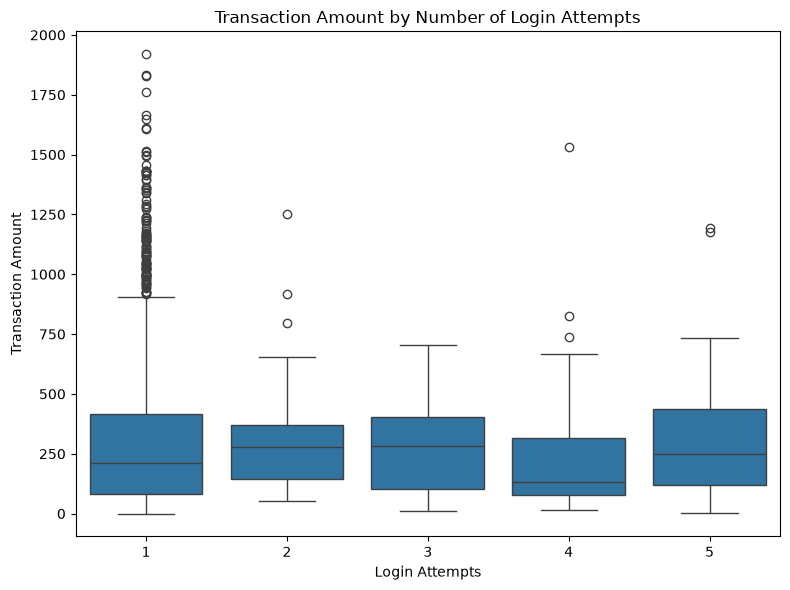

In [69]:
# Do higher login attempts correspond to larger transaction amounts?
plt.figure(figsize=(8, 6))

sns.boxplot(
    data=df_c,
    x='login_attempts',
    y='transaction_amount'
)

plt.title('Transaction Amount by Number of Login Attempts')
plt.xlabel('Login Attempts')
plt.ylabel('Transaction Amount')

plt.tight_layout()
plt.show()

In [72]:
# summary statistics
df_c.groupby('login_attempts')['transaction_seconds_duration'].describe()

,count,mean,std,min,25%,50%,75%,max
login_attempts,,,,,,,,
1,2390.0,119.128033,69.812674,10.0,63.0,111.0,161.00,300.0
2,27.0,122.185185,72.562990,19.0,60.5,124.0,163.00,280.0
3,31.0,129.032258,74.906824,13.0,67.0,127.0,167.50,286.0
4,32.0,140.968750,83.104087,11.0,76.5,129.5,187.75,291.0
5,32.0,125.562500,59.321398,22.0,90.0,126.0,156.50,283.0


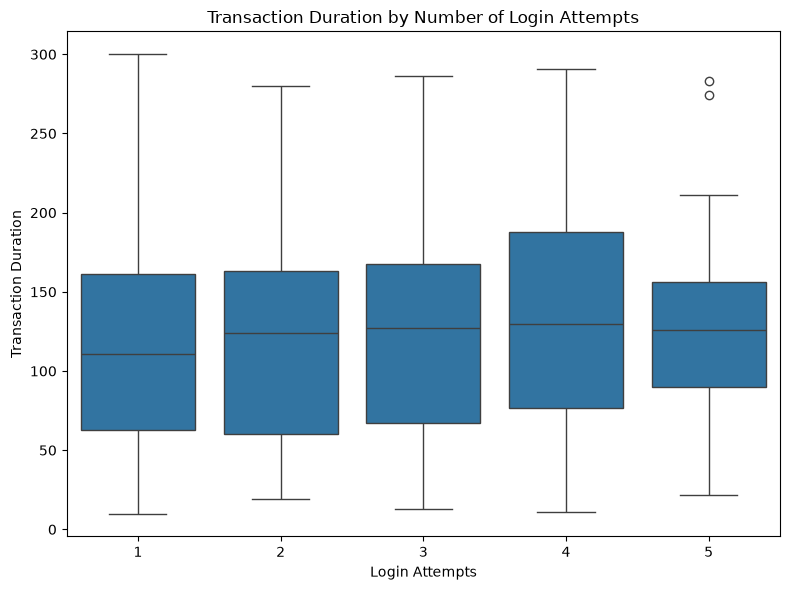

In [71]:
# Do higher transaction duration correspond to larger transaction amounts?
plt.figure(figsize=(8, 6))

sns.boxplot(
    data=df_c,
    x='login_attempts',
    y='transaction_seconds_duration'
)

plt.title('Transaction Duration by Number of Login Attempts')
plt.xlabel('Login Attempts')
plt.ylabel('Transaction Duration')

plt.tight_layout()
plt.show()

#### **2. Which channels have the highest average login attempts?**

Objective:

To compare the average number of login attempts across transaction channels and determine whether certain channels exhibit higher authentication activity, which may indicate increased access difficulty or potentially suspicious behavior.

In [73]:
# Compute the average login attempts
channel_login = (
    df_c.groupby('channel')['login_attempts']
        .mean()
        .sort_values(ascending=False)
)

channel_login

channel
Online    1.128237
ATM       1.123649
Branch    1.122120
Name: login_attempts, dtype: float64

In [74]:
# summary statistics
df_c.groupby('channel')['login_attempts'].describe()

,count,mean,std,min,25%,50%,75%,max
channel,,,,,,,,
ATM,833.0,1.123649,0.586573,1.0,1.0,1.0,1.0,5.0
Branch,868.0,1.122120,0.625354,1.0,1.0,1.0,1.0,5.0
Online,811.0,1.128237,0.594899,1.0,1.0,1.0,1.0,5.0


#### **Findings:**

The Online channel recorded the highest average number of login attempts (1.13), followed by ATM (1.12) and Branch (1.12). However, the differences across channels are minimal, with all three averaging approximately one login attempt per transaction. This suggests that login behavior is consistent regardless of the transaction channel.

#### **Business Interpretation:**

The similarity in average login attempts across Online, ATM, and Branch transactions indicates that no single channel exhibits unusually high authentication activity. Therefore, transaction channel alone is unlikely to be a strong indicator of suspicious behavior. Instead, potential fraud should be assessed by combining transaction channel with other behavioral features, such as transaction amount, login attempts, device usage, IP address changes, and transaction location.

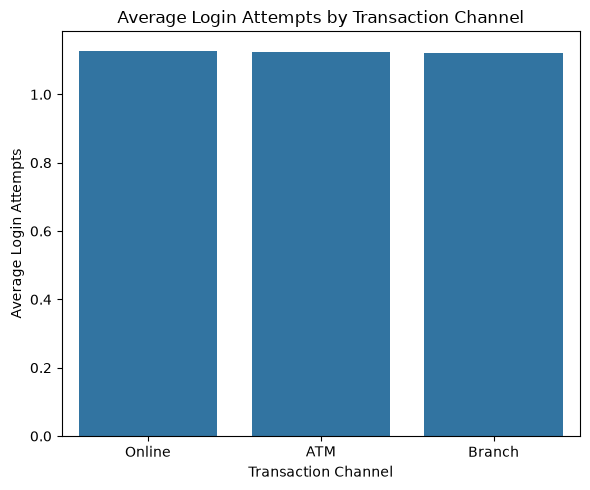

In [75]:
plt.figure(figsize=(6,5))

sns.barplot(
    x=channel_login.index,
    y=channel_login.values
)

plt.title('Average Login Attempts by Transaction Channel')
plt.xlabel('Transaction Channel')
plt.ylabel('Average Login Attempts')

plt.tight_layout()
plt.show()

#### **3. Which locations have the highest average transaction amounts?**

Objective:

To compare the average transaction amounts across locations and identify areas where higher-value transactions are more common, providing context for detecting unusual transaction behavior.

In [76]:
# get the average transaction amount by location

location_amount = (
    df_c.groupby('location')['transaction_amount']
        .mean()
        .sort_values(ascending=False)
)

location_amount

location
Austin              385.438983
El Paso             369.511957
Columbus            353.318148
Washington          351.032083
Phoenix             346.630182
Jacksonville        341.991167
San Jose            341.150339
Colorado Springs    339.077167
Portland            338.621667
Memphis             336.040159
San Antonio         327.510678
Detroit             327.139048
San Diego           325.803559
Oklahoma City       319.353529
Mesa                314.158033
Houston             308.200794
Kansas City         307.680328
Tucson              305.369552
New York            304.141897
Las Vegas           298.696909
Baltimore           297.146275
Fort Worth          296.810571
San Francisco       295.449825
Philadelphia        290.586866
Raleigh             289.863898
Los Angeles         285.155797
Indianapolis        284.878793
Omaha               283.143846
Milwaukee           277.002545
Virginia Beach      275.981091
Boston              275.298852
Chicago             270.430333

In [79]:
# summary statistics

df_c.groupby('location')['transaction_amount'].describe()

,count,mean,std,min,25%,50%,75%,max
location,,,,,,,,
Albuquerque,41.0,249.124146,246.915236,10.07,56.9600,146.670,409.5900,1021.16
Atlanta,61.0,263.151803,266.462476,1.21,73.5500,135.270,410.4900,1143.67
Austin,59.0,385.438983,382.259901,0.84,87.1150,259.490,557.3300,1397.59
Baltimore,51.0,297.146275,258.798584,2.51,133.8500,206.250,388.0200,1137.63
Boston,61.0,275.298852,258.675653,0.32,72.4700,220.200,354.9100,1087.90
Charlotte,68.0,260.039118,258.679667,3.80,67.4025,185.150,360.8350,1431.33
Chicago,60.0,270.430333,223.385172,1.93,108.6300,214.655,360.0600,830.01
Colorado Springs,60.0,339.077167,331.396127,0.86,98.6575,240.680,443.1100,1493.00
Columbus,54.0,353.318148,380.136587,6.30,61.9225,226.845,492.3875,1831.02


In [77]:
top10 = location_amount.head(10)
top10

location
Austin              385.438983
El Paso             369.511957
Columbus            353.318148
Washington          351.032083
Phoenix             346.630182
Jacksonville        341.991167
San Jose            341.150339
Colorado Springs    339.077167
Portland            338.621667
Memphis             336.040159
Name: transaction_amount, dtype: float64

#### **Findings:**

Austin recorded the highest average transaction amount (385.44), followed by El Paso (369.51) and Columbus (353.32). The remaining top 10 locations—including Washington, Phoenix, Jacksonville, San Jose, Colorado Springs, Portland, and Memphis—also exhibited relatively high average transaction values. However, the differences among these locations were modest, indicating fairly consistent transaction values across the highest-ranking locations.

#### **Business Interpretation:**

Several locations exhibit higher average transaction amounts than others, which may reflect differences in customer spending behavior within the dataset. However, high average transaction values alone should not be interpreted as evidence of fraudulent activity. For fraud detection, these transactions should be evaluated alongside additional behavioral indicators—such as login attempts, transaction frequency, device usage, IP address changes, and transaction timing—to determine whether they represent genuinely anomalous behavior.

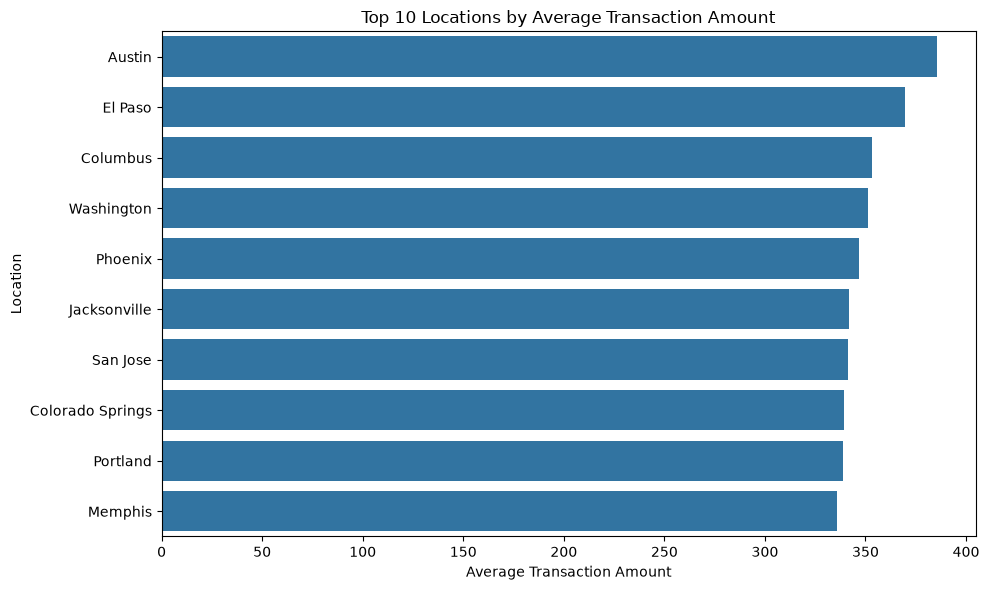

In [78]:
top10_locations = location_amount.head(10)

plt.figure(figsize=(10, 6))

sns.barplot(
    x=top10_locations.values,
    y=top10_locations.index
)

plt.title('Top 10 Locations by Average Transaction Amount')
plt.xlabel('Average Transaction Amount')
plt.ylabel('Location')

plt.tight_layout()
plt.show()

# **EDA: Behavioral Patterns**

This section focuses on identifying behavioral patterns that may indicate unusual or suspicious activity. The analysis explores:

- Which accounts frequently change devices?
- Are there transactions with unusually high amounts?
- Which accounts frequently change IP addresses?

#### **1. Which accounts frequently change devices?**
Objective:

To identify customer accounts that use multiple devices and determine whether frequent device changes may indicate unusual account access behavior.

In [80]:
devices_per_account = (
    df_c.groupby('account_id')['device_id']
        .nunique()
        .sort_values(ascending=False)
)

devices_per_account.head(10)

account_id
AC00202    12
AC00362    12
AC00460    12
AC00363    12
AC00257    11
AC00304    11
AC00456    11
AC00225    11
AC00480    10
AC00219    10
Name: device_id, dtype: int64

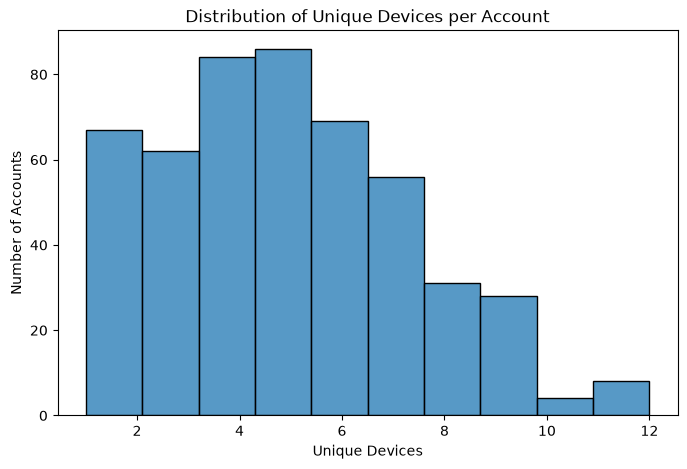

In [81]:
plt.figure(figsize=(8,5))

sns.histplot(
    devices_per_account,
    bins=10
)

plt.title('Distribution of Unique Devices per Account')
plt.xlabel('Unique Devices')
plt.ylabel('Number of Accounts')

plt.show()

In [82]:
# treat first transaction as the customer's baseline device
df_c = df_c.sort_values(['account_id', 'transaction_date'])

df_c['device_changed'] = (
    df_c.groupby('account_id')['device_id']
        .transform(lambda x: x.ne(x.shift()))
)

# First transaction of every account is NOT a change
first_idx = df_c.groupby('account_id').head(1).index
df_c.loc[first_idx, 'device_changed'] = False

In [83]:
# count how many times each account changed devices

device_changes = (
    df_c.groupby('account_id')['device_changed']
        .sum()
        .sort_values(ascending=False)
)

device_changes.head(10)

account_id
AC00460    11
AC00363    11
AC00362    11
AC00202    11
AC00480    10
AC00257    10
AC00225    10
AC00456    10
AC00304    10
AC00267     9
Name: device_changed, dtype: int64

#### **Findings:**

Several accounts were associated with a different device in nearly every transaction. For example, accounts AC00460, AC00363, AC00362, and AC00202 each completed 12 transactions using 12 unique devices, resulting in 11 device changes over time.

#### **Business Interpretation:**

Frequent device switching is commonly considered a behavioral indicator that may warrant investigation in fraud detection systems. However, because many accounts in this synthetic dataset exhibit nearly one unique device per transaction, this pattern appears to reflect the dataset's design rather than genuine customer behavior. As a result, device changes alone should not be treated as evidence of fraudulent activity and should instead be evaluated together with other indicators such as transaction amount, IP address changes, login attempts, and transaction frequency.

In [84]:
device_summary = (
    df_c.groupby('account_id')
        .agg(
            transactions=('transaction_id', 'count'),
            unique_devices=('device_id', 'nunique'),
            device_changes=('device_changed', 'sum')
        )
        .sort_values('device_changes', ascending=False)
)

device_summary.head(10)

,transactions,unique_devices,device_changes
account_id,,,
AC00460,12,12,11
AC00363,12,12,11
AC00362,12,12,11
AC00202,12,12,11
AC00480,11,10,10
AC00257,11,11,10
AC00225,11,11,10
AC00456,11,11,10
AC00304,11,11,10


#### **2. Are there transactions with unusually high amounts?**

Objective:

To identify unusually high transaction amounts and assess how they differ from the typical distribution of transaction values using the Interquartile Range (IQR) method.

#### **Upper Limit Findings:**

- Using the Interquartile Range (IQR) method, transactions with amounts exceeding 913.49 are classified as statistical outliers. A total of 113 transactions, representing 4.50% of the dataset, exceed this threshold. These observations were retained for further analysis because the objective of this study is to identify anomalous transaction behavior. While statistical outliers are not necessarily fraudulent, they represent unusual transaction patterns that warrant further investigation during the anomaly detection stage.

In [86]:
# how many observations exceed the upper limit:

outliers = df_c[df_c['transaction_amount'] > upper_limit]
pct_outliers = (len(outliers) / len(df_c)) * 100


print("Result: ")
print("---"*8)
print(f"Number of outliers: {len(outliers)}")
print(f"Percentage of Outliers: {pct_outliers:.2f}%")

Result: 
------------------------
Number of outliers: 113
Percentage of Outliers: 4.50%


In [85]:
# these are the rows that exceed the upper limit of the transaction amount

outliers = df_c[df_c['transaction_amount'] > upper_limit]
outliers

,transaction_id,account_id,transaction_amount,transaction_date,transaction_type,location,device_id,ip_address,merchant_id,channel,customer_age,customer_occupation,transaction_seconds_duration,login_attempts,account_balance,previous_transaction_date,device_changed
1759,TX001760,AC00010,1086.60,2023-05-22 17:40:46,Debit,San Diego,D000428,74.58.165.67,M016,Online,19,Student,38,1,1605.67,2024-11-04 08:10:48,True
2151,TX002152,AC00012,927.45,2023-08-07 18:52:42,Debit,Austin,D000210,176.96.83.253,M027,ATM,24,Student,95,1,1161.84,2024-11-04 08:07:13,True
2334,TX002335,AC00016,1105.88,2023-03-06 17:37:32,Debit,Omaha,D000159,41.82.55.163,M047,ATM,34,Engineer,36,1,2636.32,2024-11-04 08:11:22,True
1497,TX001498,AC00018,1228.81,2023-02-20 16:36:36,Debit,San Francisco,D000381,63.191.171.41,M034,ATM,26,Student,254,1,1821.00,2024-11-04 08:09:05,False
1997,TX001998,AC00021,1142.83,2023-07-14 17:44:23,Credit,Omaha,D000493,219.98.242.240,M028,Branch,61,Retired,48,1,2467.39,2024-11-04 08:11:26,True
2414,TX002415,AC00028,1664.33,2023-09-25 17:11:19,Debit,San Antonio,D000072,116.106.207.139,M064,Branch,18,Student,65,1,1588.31,2024-11-04 08:07:07,True
2086,TX002087,AC00029,1192.95,2023-12-04 18:30:00,Debit,Las Vegas,D000227,71.93.189.160,M068,Branch,23,Student,73,1,325.15,2024-11-04 08:08:01,True
753,TX000754,AC00032,1020.73,2023-07-24 16:42:06,Debit,Fort Worth,D000676,166.79.195.157,M087,ATM,28,Student,87,1,1119.61,2024-11-04 08:11:32,True
440,TX000441,AC00040,1237.56,2023-11-13 17:49:04,Credit,Austin,D000077,219.96.187.255,M060,Branch,60,Engineer,159,1,9410.17,2024-11-04 08:11:45,True
1516,TX001517,AC00040,965.66,2023-12-18 17:22:16,Debit,Raleigh,D000244,81.102.230.41,M009,ATM,53,Engineer,32,1,765.81,2024-11-04 08:08:58,True


#### **3. Which accounts frequently change IP addresses?**
Objective:

To identify customer accounts associated with multiple IP addresses and determine whether frequent IP address changes may indicate unusual account access behavior.

In [87]:
# count unique ips

ip_per_account = (
    df_c.groupby('account_id')['ip_address']
    .nunique()
    .sort_values(ascending=False)
)

ip_per_account.head()

account_id
AC00202    12
AC00460    12
AC00363    12
AC00362    12
AC00480    11
Name: ip_address, dtype: int64

In [91]:
# descriptive stats

ip_per_account.describe()

count    495.000000
mean       5.048485
std        2.273254
min        1.000000
25%        3.000000
50%        5.000000
75%        7.000000
max       12.000000
Name: ip_address, dtype: float64

In [92]:
# check median
ip_per_account.median()

np.float64(5.0)

#### **Findings:**

Each account is associated with an average of 5 unique IP addresses (mean = 5.05, median = 5), with most accounts using between 3 and 7 IP addresses. The number of unique IP addresses ranged from 1 to 12, with accounts AC00202, AC00460, AC00363, and AC00362 exhibiting the highest observed count of 12 unique IP addresses.

#### **Business Interpretation:**

Using multiple IP addresses appears to be a common customer behavior, likely reflecting access from different networks or locations. However, accounts associated with an unusually high number of IP addresses may warrant additional review, particularly when combined with other risk indicators such as frequent device changes, high-value transactions, or multiple login attempts, as these patterns may indicate potentially anomalous account activity.

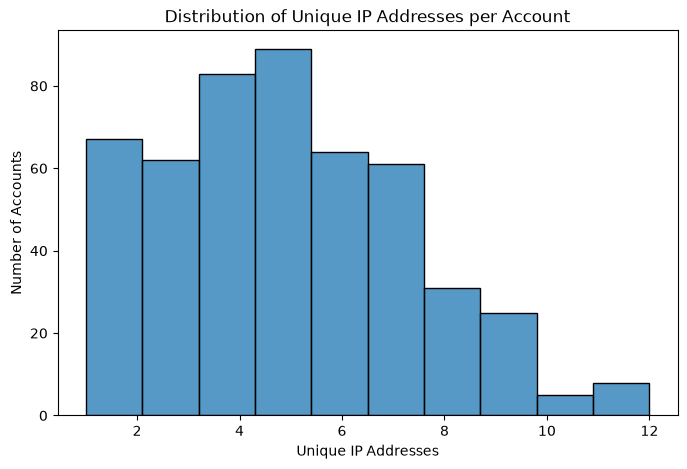

In [88]:
plt.figure(figsize=(8,5))

sns.histplot(
    ip_per_account,
    bins=10
)

plt.title('Distribution of Unique IP Addresses per Account')
plt.xlabel('Unique IP Addresses')
plt.ylabel('Number of Accounts')

plt.show()

# **Feature Engineering**

In [89]:
# to identify accounts that actually switched IPs most often

df_c = df_c.sort_values(['account_id','transaction_date'])

df_c['ip_changed'] = (
    df_c.groupby('account_id')['ip_address']
        .transform(lambda x: x != x.shift())
)

ip_changes = (
    df_c.groupby('account_id')['ip_changed']
        .sum()
        .sort_values(ascending=False)
)

In [93]:
# convert datets to datetime formats
df_c['transaction_date'] = pd.to_datetime(
    df_c['transaction_date'],
    errors='coerce'
)

df_c['previous_transaction_date'] = pd.to_datetime(
    df_c['previous_transaction_date'],
    errors='coerce'
)

In [95]:
# inspect dtypes
df_c[['transaction_date', 'previous_transaction_date']].dtypes

transaction_date             datetime64[us]
previous_transaction_date    datetime64[us]
dtype: object

In [96]:
# check for conversion concerns
df_c[['transaction_date', 'previous_transaction_date']].isna().sum()

transaction_date             0
previous_transaction_date    0
dtype: int64

In [97]:
# create fraud-related features

# Hour of transaction
df_c['transaction_hour'] = df_c['transaction_date'].dt.hour

# Day of week
df_c['day_of_week'] = df_c['transaction_date'].dt.day_name()

# Weekend flag
df_c['is_weekend'] = df_c['transaction_date'].dt.dayofweek >= 5

# Time since previous transaction
df_c['time_since_previous'] = (
    df_c['transaction_date'] - df_c['previous_transaction_date']
).dt.total_seconds() / 60  # minutes

In [98]:
# transaction-balance ratio
df_c['amount_balance_ratio'] = (
    df_c['transaction_amount'] /
    df_c['account_balance']
)

# high-value transaction flag
df_c['high_value_transaction'] = (
    df_c['transaction_amount'] > upper_limit
)

In [99]:
df_c.info()

<class 'pandas.DataFrame'>
Index: 2512 entries, 1312 to 2349
Data columns (total 24 columns):
 #   Column                        Non-Null Count  Dtype         
---  ------                        --------------  -----         
 0   transaction_id                2512 non-null   str           
 1   account_id                    2512 non-null   str           
 2   transaction_amount            2512 non-null   float64       
 3   transaction_date              2512 non-null   datetime64[us]
 4   transaction_type              2512 non-null   str           
 5   location                      2512 non-null   str           
 6   device_id                     2512 non-null   str           
 7   ip_address                    2512 non-null   str           
 8   merchant_id                   2512 non-null   str           
 9   channel                       2512 non-null   str           
 10  customer_age                  2512 non-null   int64         
 11  customer_occupation           2512 non-null

# **Feature Transformation**

In [100]:
id_cols = [
    'transaction_id',
    'account_id',
    'device_id',
    'ip_address',
    'merchant_id',
    'transaction_date',
    'previous_transaction_date'
]

df_model = df_c.drop(columns=id_cols)
df_model.info()

<class 'pandas.DataFrame'>
Index: 2512 entries, 1312 to 2349
Data columns (total 17 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   transaction_amount            2512 non-null   float64
 1   transaction_type              2512 non-null   str    
 2   location                      2512 non-null   str    
 3   channel                       2512 non-null   str    
 4   customer_age                  2512 non-null   int64  
 5   customer_occupation           2512 non-null   str    
 6   transaction_seconds_duration  2512 non-null   int64  
 7   login_attempts                2512 non-null   int64  
 8   account_balance               2512 non-null   float64
 9   device_changed                2512 non-null   bool   
 10  ip_changed                    2512 non-null   bool   
 11  transaction_hour              2512 non-null   int32  
 12  day_of_week                   2512 non-null   str    
 13  is_weekend      

In [101]:
# separate numerical and categorical columns

cat_cols = df_model.select_dtypes(include='object').columns

num_cols = df_model.select_dtypes(include=['int64', 'int32', 'float64', 'bool']).columns

print("Categorical Columns:")
print(cat_cols)

print("\nNumerical Columns:")
print(num_cols)

Categorical Columns:
Index(['transaction_type', 'location', 'channel', 'customer_occupation',
       'day_of_week'],
      dtype='str')

Numerical Columns:
Index(['transaction_amount', 'customer_age', 'transaction_seconds_duration',
       'login_attempts', 'account_balance', 'device_changed', 'ip_changed',
       'transaction_hour', 'is_weekend', 'time_since_previous',
       'amount_balance_ratio', 'high_value_transaction'],
      dtype='str')


C:\Users\admin\AppData\Local\Temp\ipykernel_11988\3496024188.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = df_model.select_dtypes(include='object').columns


In [102]:
# one-hot encode categorical values

df_model = pd.get_dummies(
    df_model,
    columns=cat_cols,
    drop_first=True
)

df_model.head()

,transaction_amount,customer_age,transaction_seconds_duration,login_attempts,account_balance,device_changed,ip_changed,transaction_hour,is_weekend,time_since_previous,amount_balance_ratio,high_value_transaction,transaction_type_Debit,location_Atlanta,location_Austin,location_Baltimore,location_Boston,location_Charlotte,location_Chicago,location_Colorado Springs,location_Columbus,location_Dallas,location_Denver,location_Detroit,location_El Paso,location_Fort Worth,location_Fresno,location_Houston,location_Indianapolis,location_Jacksonville,location_Kansas City,location_Las Vegas,location_Los Angeles,location_Louisville,location_Memphis,location_Mesa,location_Miami,location_Milwaukee,location_Nashville,location_New York,location_Oklahoma City,location_Omaha,location_Philadelphia,location_Phoenix,location_Portland,location_Raleigh,location_Sacramento,location_San Antonio,location_San Diego,location_San Francisco,location_San Jose,location_Seattle,location_Tucson,location_Virginia Beach,location_Washington,channel_Branch,channel_Online,customer_occupation_Engineer,customer_occupation_Retired,customer_occupation_Student,day_of_week_Monday,day_of_week_Thursday,day_of_week_Tuesday,day_of_week_Wednesday
1312,47.79,25,37,1,1649.92,False,True,17,False,-598511.583333,0.028965,False,True,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,True,False,False,False,False
2016,212.97,59,178,1,4180.40,True,True,16,False,-512114.133333,0.050945,False,True,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,True,False,False,False,False,True,False
2120,476.99,23,187,1,1154.48,False,True,16,False,-955689.633333,0.413164,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,True,False,False,True,False,False,True,False
20,59.32,71,38,1,5750.89,True,True,16,False,-885092.433333,0.010315,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,True,False,False,False,True,False
1476,12.62,33,61,1,6420.47,True,True,16,False,-790053.316667,0.001966,False,True,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False


In [103]:
df_model.info()

<class 'pandas.DataFrame'>
Index: 2512 entries, 1312 to 2349
Data columns (total 64 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   transaction_amount            2512 non-null   float64
 1   customer_age                  2512 non-null   int64  
 2   transaction_seconds_duration  2512 non-null   int64  
 3   login_attempts                2512 non-null   int64  
 4   account_balance               2512 non-null   float64
 5   device_changed                2512 non-null   bool   
 6   ip_changed                    2512 non-null   bool   
 7   transaction_hour              2512 non-null   int32  
 8   is_weekend                    2512 non-null   bool   
 9   time_since_previous           2512 non-null   float64
 10  amount_balance_ratio          2512 non-null   float64
 11  high_value_transaction        2512 non-null   bool   
 12  transaction_type_Debit        2512 non-null   bool   
 13  location_Atlanta

#### **Explanation:**
RobustScaler was applied to numerical features to reduce the influence of extreme values while preserving anomalous observations. Since the dataset contains several outliers, robust scaling provides a more stable feature representation than mean-based scaling methods, particularly for distance-based anomaly detection algorithms such as Local Outlier Factor.

In [104]:
# scale dataset
scaler = RobustScaler()

num_cols = [
    'transaction_amount',
    'customer_age',
    'transaction_seconds_duration',
    'login_attempts',
    'account_balance',
    'transaction_hour',
    'time_since_previous',
    'amount_balance_ratio'
  ]

df_model[num_cols] = scaler.fit_transform(df_model[num_cols])


# **Model Training: Isolation Forest Algorithm**

Isolation Forest was selected because it is an efficient unsupervised anomaly detection algorithm that does not require labeled fraud data. It isolates anomalous observations through random partitioning, making it well suited for identifying unusual transaction patterns in financial datasets. Compared with clustering methods and One-Class SVM, Isolation Forest is computationally efficient, scalable, and less sensitive to parameter tuning. Local Outlier Factor (LOF) was subsequently implemented to validate the consistency of the detected anomalies using a complementary density-based approach.

In [105]:
# prepare preprocessed dataset
x = df_model.copy()

In [106]:
# create model
# build 100 random isolation trees
# 5% of anomalous data


iso = IsolationForest(
    n_estimators=100,
    contamination=0.05,
    random_state=42
)

In [108]:
# fit the model
# model learns what "normal" behaviour looks like
iso.fit(x)

,"contamination contamination: 'auto' or float, default='auto'The amount of contamination of the data set, i.e. the proportionof outliers in the data set. Used when fitting to define the thresholdon the scores of the samples.- If 'auto', the threshold is determined as in the original paper.- If float, the contamination should be in the range (0, 0.5]... versionchanged:: 0.22 The default value of ``contamination`` changed from 0.1 to ``'auto'``.",0.05
,"random_state random_state: int, RandomState instance or None, default=NoneControls the pseudo-randomness of the selection of the featureand split values for each branching step and each tree in the forest.Pass an int for reproducible results across multiple function calls.See :term:`Glossary <random_state>`.",42
,"n_estimators n_estimators: int, default=100The number of base estimators in the ensemble.",100
,"max_samples max_samples: ""auto"", int or float, default=""auto""The number of samples to draw from X to train each base estimator.- If int, then draw `max_samples` samples.- If float, then draw `max_samples * X.shape[0]` samples.- If ""auto"", then `max_samples=min(256, n_samples)`.If max_samples is larger than the number of samples provided,all samples will be used for all trees (no sampling).",'auto'
,"max_features max_features: int or float, default=1.0The number of features to draw from X to train each base estimator.- If int, then draw `max_features` features.- If float, then draw `max(1, int(max_features * n_features_in_))` features.Note: using a float number less than 1.0 or integer less than number offeatures will enable feature subsampling and leads to a longer runtime.",1.0
,"bootstrap bootstrap: bool, default=FalseIf True, individual trees are fit on random subsets of the trainingdata sampled with replacement. If False, sampling without replacementis performed.",False
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel for :meth:`fit`. ``None`` means 1unless in a :obj:`joblib.parallel_backend` context. ``-1`` means usingall processors. See :term:`Glossary <n_jobs>` for more details.",None
,"verbose verbose: int, default=0Controls the verbosity of the tree building process.",0
,"warm_start warm_start: bool, default=FalseWhen set to ``True``, reuse the solution of the previous call to fitand add more estimators to the ensemble, otherwise, just fit a wholenew forest. See :term:`the Glossary <warm_start>`... versionadded:: 0.21",False
Name,Type,Value
estimator_ estimator_: :class:`~sklearn.tree.ExtraTreeRegressor` instanceThe child estimator template used to create the collection offitted sub-estimators... versionadded:: 1.2 `base_estimator_` was renamed to `estimator_`.,ExtraTreeRegressor,ExtraTreeRegr...ndom_state=42)


In [109]:
# predict anomalies
# 1 = normal transaction
# -1 = anomalous transaction

df_c['anomaly'] = iso.predict(x)

In [110]:
# convert to readable labels

df_c['fraud_flag'] = df_c['anomaly'].map({
    1:'Normal',
    -1: 'Potential Fraud'
})

df_c['fraud_flag'].value_counts()

fraud_flag
Normal             2386
Potential Fraud     126
Name: count, dtype: int64

#### **Findings:**

The Isolation Forest model identified 126 transactions (5.02% of the dataset) as potential anomalies. These transactions represent observations whose behavior differs from the majority of transactions and may warrant further investigation for possible fraud.

In [111]:
pct = (
    (df_c['fraud_flag'] == 'Potential Fraud')
    .mean() * 100
)

print(f"Potential Fraud: {pct:.2f}%")

Potential Fraud: 5.02%


In [112]:
# reveal suspicious transactions
fraud_cases = df_c[df_c['fraud_flag'] == 'Potential Fraud']

fraud_cases.head()

,transaction_id,account_id,transaction_amount,transaction_date,transaction_type,location,device_id,ip_address,merchant_id,channel,customer_age,customer_occupation,transaction_seconds_duration,login_attempts,account_balance,previous_transaction_date,device_changed,ip_changed,transaction_hour,day_of_week,is_weekend,time_since_previous,amount_balance_ratio,high_value_transaction,anomaly,fraud_flag
706,TX000707,AC00004,642.54,2023-05-10 18:49:20,Debit,Milwaukee,D000663,166.79.195.157,M025,Branch,44,Engineer,28,1,3143.17,2024-11-04 08:10:37,True,True,18,Wednesday,False,-782721.283333,0.204424,False,-1,Potential Fraud
2511,TX002512,AC00009,243.08,2023-02-14 16:21:23,Credit,Jacksonville,D000215,59.127.135.25,M041,Online,24,Student,93,1,131.25,2024-11-04 08:07:49,False,True,16,Tuesday,False,-905266.433333,1.852038,False,-1,Potential Fraud
693,TX000694,AC00011,733.29,2023-03-15 18:42:16,Debit,Virginia Beach,D000618,16.51.235.240,M032,ATM,52,Doctor,94,5,10427.00,2024-11-04 08:07:12,False,True,18,Wednesday,False,-863364.933333,0.070326,False,-1,Potential Fraud
2151,TX002152,AC00012,927.45,2023-08-07 18:52:42,Debit,Austin,D000210,176.96.83.253,M027,ATM,24,Student,95,1,1161.84,2024-11-04 08:07:13,True,True,18,Monday,False,-654554.516667,0.798260,True,-1,Potential Fraud
2334,TX002335,AC00016,1105.88,2023-03-06 17:37:32,Debit,Omaha,D000159,41.82.55.163,M047,ATM,34,Engineer,36,1,2636.32,2024-11-04 08:11:22,True,True,17,Monday,False,-876393.833333,0.419479,True,-1,Potential Fraud


In [113]:
# check fraud score
df_c['anomaly_score'] = iso.decision_function(x)

df_c.sort_values('anomaly_score').head(10)

,transaction_id,account_id,transaction_amount,transaction_date,transaction_type,location,device_id,ip_address,merchant_id,channel,customer_age,customer_occupation,transaction_seconds_duration,login_attempts,account_balance,previous_transaction_date,device_changed,ip_changed,transaction_hour,day_of_week,is_weekend,time_since_previous,amount_balance_ratio,high_value_transaction,anomaly,fraud_flag,anomaly_score
274,TX000275,AC00454,1176.28,2023-12-20 16:08:02,Credit,Kansas City,D000476,50.202.8.53,M074,ATM,54,Engineer,174,5,323.69,2024-11-04 08:11:44,True,True,16,Wednesday,False,-460323.700000,3.633971,True,-1,Potential Fraud,-0.070126
614,TX000615,AC00466,1342.25,2023-04-28 18:11:55,Credit,Fort Worth,D000643,28.149.72.129,M032,Branch,21,Student,235,1,694.03,2024-11-04 08:08:00,False,True,18,Friday,False,-800036.083333,1.933994,True,-1,Potential Fraud,-0.057688
1213,TX001214,AC00170,1192.20,2023-12-21 16:21:27,Credit,Jacksonville,D000174,40.10.25.102,M093,Branch,60,Retired,103,5,7816.41,2024-11-04 08:09:14,True,True,16,Thursday,False,-458867.783333,0.152525,True,-1,Potential Fraud,-0.054845
1273,TX001274,AC00431,1235.69,2023-05-24 16:14:34,Credit,San Jose,D000216,69.82.61.135,M048,Branch,20,Student,118,1,420.25,2024-11-04 08:09:22,True,True,16,Wednesday,False,-762714.800000,2.940369,True,-1,Potential Fraud,-0.053773
934,TX000935,AC00456,1022.75,2023-01-19 16:45:16,Credit,San Jose,D000294,190.164.160.79,M091,Branch,62,Doctor,158,1,207.74,2024-11-04 08:10:47,True,True,16,Thursday,False,-942685.516667,4.923221,True,-1,Potential Fraud,-0.047734
74,TX000075,AC00265,1212.51,2023-10-04 16:36:29,Debit,Indianapolis,D000231,193.83.0.183,M036,Branch,20,Student,24,1,605.95,2024-11-04 08:06:51,True,True,16,Wednesday,False,-571170.366667,2.001007,True,-1,Potential Fraud,-0.045930
311,TX000312,AC00285,1221.65,2023-09-27 16:55:35,Debit,Denver,D000098,83.207.115.164,M091,Online,27,Student,153,1,243.92,2024-11-04 08:10:41,True,True,16,Wednesday,False,-581235.100000,5.008404,True,-1,Potential Fraud,-0.042192
1984,TX001985,AC00303,1512.99,2023-08-08 17:15:50,Debit,Philadelphia,D000032,195.164.171.146,M071,Online,19,Student,50,1,9963.39,2024-11-04 08:09:45,False,True,17,Tuesday,False,-653213.916667,0.151855,True,-1,Potential Fraud,-0.039399
147,TX000148,AC00161,514.95,2023-04-13 18:37:48,Debit,New York,D000109,23.92.205.75,M056,Online,41,Doctor,142,5,421.93,2024-11-04 08:10:01,False,True,18,Thursday,False,-821612.216667,1.220463,False,-1,Potential Fraud,-0.036683
1952,TX001953,AC00350,1496.57,2023-02-27 16:18:28,Debit,Memphis,D000139,182.84.41.229,M092,Online,33,Engineer,95,1,969.06,2024-11-04 08:06:37,False,True,16,Monday,False,-886548.150000,1.544352,True,-1,Potential Fraud,-0.033565


### **Transaction Amount**

#### **Findings:**

Potentially fraudulent transactions have a much higher average transaction amount (829.65) compared to normal transactions (269.50).
The median transaction amount for potential fraud (962.57) is nearly five times higher than that of normal transactions (200.02).
This indicates that the model primarily flagged transactions involving unusually large monetary values.

#### **Business Interpretation:**

The Isolation Forest model identified high-value transactions as a major source of anomalous behavior. Large transaction amounts deviate substantially from typical customer spending patterns and should be prioritized for further fraud investigation.

In [114]:
df_c.groupby('fraud_flag')['transaction_amount'].describe()

,count,mean,std,min,25%,50%,75%,max
fraud_flag,,,,,,,,
Normal,2386.0,269.497079,246.934102,0.26,79.3700,200.015,385.1150,1919.11
Potential Fraud,126.0,829.647143,498.305133,1.93,327.5375,962.570,1192.7625,1830.00


### **Login Attempts**

#### **Findings:**
Potentially fraudulent transactions required an average of 1.67 login attempts, compared to 1.10 for normal transactions.
Although most transactions were completed with a single login attempt, flagged transactions exhibited greater variability, with some requiring up to five login attempts.

#### **Business Interpretation:**

Transactions requiring multiple login attempts appear more likely to be considered anomalous. Repeated login attempts may indicate authentication difficulties or unauthorized access attempts, making them useful behavioral indicators during fraud investigations.

In [116]:
df_c.groupby('fraud_flag')['login_attempts'].describe()

,count,mean,std,min,25%,50%,75%,max
fraud_flag,,,,,,,,
Normal,2386.0,1.095977,0.515187,1.0,1.0,1.0,1.0,5.0
Potential Fraud,126.0,1.666667,1.385641,1.0,1.0,1.0,1.0,5.0


### **Account Balance**
#### **Findings:**
Potentially fraudulent transactions were associated with lower average account balances (3,763.55) compared to normal transactions (5,185.63).
The median account balance for flagged transactions (2,038.08) is substantially lower than that of normal transactions (4,878.09).

#### **Business Interpretation:**

The model suggests that anomalous transactions are more frequently associated with accounts holding relatively lower balances. When combined with unusually large transaction amounts, this behavior may represent transactions that consume a significant portion of the available funds.

In [117]:
df_c.groupby('fraud_flag')['account_balance'].describe()

,count,mean,std,min,25%,50%,75%,max
fraud_flag,,,,,,,,
Normal,2386.0,5185.633562,3894.088193,101.25,1545.6725,4878.085,7741.7825,14977.99
Potential Fraud,126.0,3763.550556,3797.667365,102.20,759.0075,2038.080,6345.0350,14851.28


### **Device Changes**
#### **Findings:**
Approximately 81.1% of normal transactions involved a device change, compared to 65.1% of potentially fraudulent transactions.
Device changes were slightly less common among the transactions flagged by the model.

#### **Business Interpretation:**

Device changes were not a primary factor driving the model's anomaly detection in this dataset. This suggests that switching devices is relatively common customer behavior and, by itself, may not reliably indicate suspicious activity.

Note: This is actually an interesting finding because it contradicts what we might initially expect. It's perfectly acceptable to report that the model did not find device changes to be a distinguishing characteristic of anomalous transactions.

In [118]:
df_c.groupby('fraud_flag')['device_changed'].mean()

fraud_flag
Normal             0.810562
Potential Fraud    0.650794
Name: device_changed, dtype: float64

### **IP Address Changes**
#### **Findings:**
100% of potentially fraudulent transactions involved an IP address change.
Nearly all normal transactions (99.83%) also involved an IP address change.

#### **Business Interpretation:**

IP address changes provide little discriminatory value in this dataset because they occur in almost every transaction regardless of whether it was flagged as anomalous. Consequently, IP changes alone are not effective indicators of suspicious behavior in this analysis.

This is another valuable finding. Not every feature contributes equally to anomaly detection, and identifying features with limited predictive value is an important part of model interpretation.

In [119]:
df_c.groupby('fraud_flag')['ip_changed'].mean()

fraud_flag
Normal             0.998324
Potential Fraud    1.000000
Name: ip_changed, dtype: float64

### **Model Performance for Isolation Forest**
Since the dataset does not contain labeled fraud cases, traditional classification metrics such as accuracy, precision, recall, and F1-score cannot be computed. Instead, the Isolation Forest model was evaluated by examining whether the detected anomalies exhibited meaningful behavioral differences from normal transactions. The flagged transactions consistently showed substantially higher transaction amounts, more login attempts, and lower account balances, which align with expected indicators of anomalous financial behavior. This suggests that the model successfully identified transactions that deviate from typical customer activity.



**Limitation:** Because the dataset does not contain verified fraud labels, the model identifies potential anomalies rather than confirmed fraudulent transactions. Consequently, the results should be interpreted as transactions requiring further investigation instead of definitive fraud cases.

### **Overall Model Findings:**

The Isolation Forest model flagged 126 transactions (5.02%) as potential anomalies. These transactions were primarily characterized by substantially higher transaction amounts, more login attempts, and lower account balances compared to normal transactions. In contrast, device changes and IP address changes contributed little to distinguishing anomalous transactions, suggesting that unusual transaction value and authentication behavior were the strongest indicators identified by the model.

### 

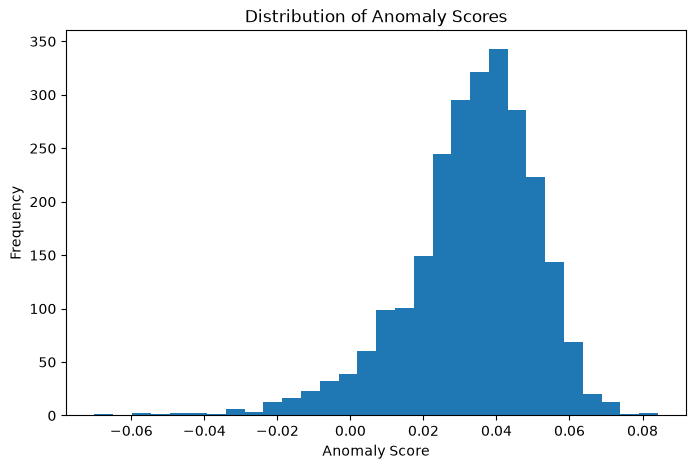

In [120]:
# decision function distribution
plt.figure(figsize=(8,5))

plt.hist(df_c['anomaly_score'], bins=30)

plt.xlabel("Anomaly Score")
plt.ylabel("Frequency")
plt.title("Distribution of Anomaly Scores")

plt.show()

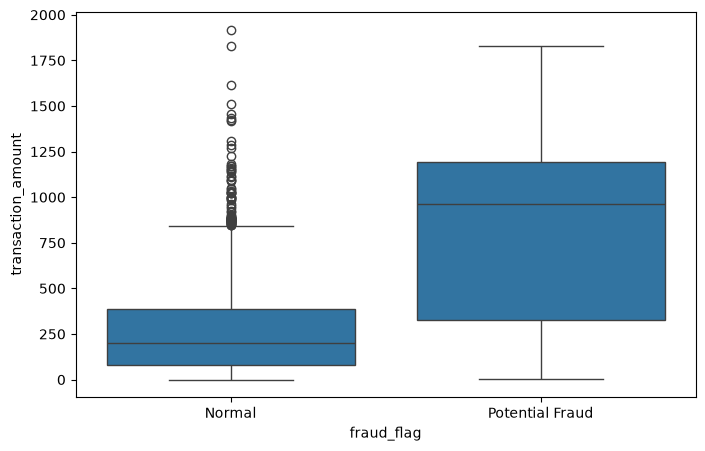

In [121]:
# flagged transactions
# if the Potential Fraud box is noticeably higher than the Normal box,
# that's evidence that the model separated transactions with different characteristics

plt.figure(figsize=(8,5))

sns.boxplot(
    data=df_c,
    x='fraud_flag',
    y='transaction_amount'
)

plt.show()

# **Model Training: Local Outlier Factor Algorithm**

Local Outlier Factor (LOF) was implemented as a complementary unsupervised anomaly detection algorithm to validate the results of the Isolation Forest model. Unlike Isolation Forest, which isolates observations using random partitioning, LOF identifies anomalies by comparing the local density of each transaction with that of its nearest neighbors. Using both models enabled a comparative analysis of anomaly detection methods and increased confidence in transactions consistently flagged as anomalous.

In [122]:
# create model
lof = LocalOutlierFactor(
    n_neighbors=20,
    contamination=0.05
)

# train model
df_c['lof_prediction'] = lof.fit_predict(x)

In [123]:
# conver to readable labels
df_c['lof_flag'] = df_c['lof_prediction'].map({
    1: 'Normal',
    -1: 'Potential Fraud'
})

# count anomalies
df_c['lof_flag'].value_counts()

lof_flag
Normal             2386
Potential Fraud     126
Name: count, dtype: int64

#### **Findings:**

The Local Outlier Factor (LOF) model identified 126 transactions (5%) as potential anomalies, while 2,386 transactions (95%) were classified as normal. This indicates that only a small proportion of transactions exhibited local behavioral patterns that deviated from their neighboring observations.

#### **Business Interpretation:**

The transactions flagged by LOF represent accounts whose behavior differs significantly from similar transactions in the dataset. These anomalies should be prioritized for further investigation, as they may indicate unusual customer activity or potential fraudulent behavior that warrants closer review.

# **Model Comparison**

In [124]:
# compare with isolation forest
# Rows = Isolation Forest's prediction
# Columns = LOF's prediction

pd.crosstab(
    df_c['fraud_flag'],
    df_c['lof_flag']
)

lof_flag,Normal,Potential Fraud
fraud_flag,,
Normal,2303,83
Potential Fraud,83,43


In [125]:
# how often the two models agree
agreement = (
    df_c['fraud_flag'] ==
    df_c['lof_flag']
).mean() * 100

print(f"Agreement: {agreement:.2f}%")

Agreement: 93.39%


In [126]:
# transactions flagged by both models

both_models = df_c[
    (df_c['fraud_flag'] == 'Potential Fraud') &
    (df_c['lof_flag'] == 'Potential Fraud')
]

both_models.head()

,transaction_id,account_id,transaction_amount,transaction_date,transaction_type,location,device_id,ip_address,merchant_id,channel,customer_age,customer_occupation,transaction_seconds_duration,login_attempts,account_balance,previous_transaction_date,device_changed,ip_changed,transaction_hour,day_of_week,is_weekend,time_since_previous,amount_balance_ratio,high_value_transaction,anomaly,fraud_flag,anomaly_score,lof_prediction,lof_flag
706,TX000707,AC00004,642.54,2023-05-10 18:49:20,Debit,Milwaukee,D000663,166.79.195.157,M025,Branch,44,Engineer,28,1,3143.17,2024-11-04 08:10:37,True,True,18,Wednesday,False,-782721.283333,0.204424,False,-1,Potential Fraud,-0.000236,-1,Potential Fraud
1258,TX001259,AC00020,603.23,2023-08-24 17:34:13,Debit,Detroit,D000238,38.210.156.148,M017,Branch,28,Student,48,1,117.98,2024-11-04 08:08:18,True,True,17,Thursday,False,-630154.083333,5.112985,False,-1,Potential Fraud,-0.007965,-1,Potential Fraud
2086,TX002087,AC00029,1192.95,2023-12-04 18:30:00,Debit,Las Vegas,D000227,71.93.189.160,M068,Branch,23,Student,73,1,325.15,2024-11-04 08:08:01,True,True,18,Monday,False,-483218.016667,3.668922,True,-1,Potential Fraud,-0.030903,-1,Potential Fraud
1447,TX001448,AC00080,991.82,2023-12-04 16:16:19,Debit,Milwaukee,D000496,62.152.134.92,M042,Online,43,Engineer,300,1,3493.13,2024-11-04 08:10:11,True,True,16,Monday,False,-483353.866667,0.283934,True,-1,Potential Fraud,-0.008622,-1,Potential Fraud
898,TX000899,AC00083,1531.31,2023-10-23 18:00:29,Debit,San Diego,D000319,91.204.200.167,M078,Online,18,Student,62,4,859.86,2024-11-04 08:06:40,True,True,18,Monday,False,-543726.183333,1.780883,True,-1,Potential Fraud,-0.033218,-1,Potential Fraud


In [127]:
# transactions flagged only by Isolation Forest
iso_only = df_c[
    (df_c['fraud_flag'] == 'Potential Fraud') &
    (df_c['lof_flag'] == 'Normal')
]

iso_only

,transaction_id,account_id,transaction_amount,transaction_date,transaction_type,location,device_id,ip_address,merchant_id,channel,customer_age,customer_occupation,transaction_seconds_duration,login_attempts,account_balance,previous_transaction_date,device_changed,ip_changed,transaction_hour,day_of_week,is_weekend,time_since_previous,amount_balance_ratio,high_value_transaction,anomaly,fraud_flag,anomaly_score,lof_prediction,lof_flag
2511,TX002512,AC00009,243.08,2023-02-14 16:21:23,Credit,Jacksonville,D000215,59.127.135.25,M041,Online,24,Student,93,1,131.25,2024-11-04 08:07:49,False,True,16,Tuesday,False,-905266.433333,1.852038,False,-1,Potential Fraud,-0.008923,1,Normal
693,TX000694,AC00011,733.29,2023-03-15 18:42:16,Debit,Virginia Beach,D000618,16.51.235.240,M032,ATM,52,Doctor,94,5,10427.00,2024-11-04 08:07:12,False,True,18,Wednesday,False,-863364.933333,0.070326,False,-1,Potential Fraud,-0.013981,1,Normal
2151,TX002152,AC00012,927.45,2023-08-07 18:52:42,Debit,Austin,D000210,176.96.83.253,M027,ATM,24,Student,95,1,1161.84,2024-11-04 08:07:13,True,True,18,Monday,False,-654554.516667,0.798260,True,-1,Potential Fraud,-0.004252,1,Normal
2334,TX002335,AC00016,1105.88,2023-03-06 17:37:32,Debit,Omaha,D000159,41.82.55.163,M047,ATM,34,Engineer,36,1,2636.32,2024-11-04 08:11:22,True,True,17,Monday,False,-876393.833333,0.419479,True,-1,Potential Fraud,-0.004808,1,Normal
1497,TX001498,AC00018,1228.81,2023-02-20 16:36:36,Debit,San Francisco,D000381,63.191.171.41,M034,ATM,26,Student,254,1,1821.00,2024-11-04 08:09:05,False,True,16,Monday,False,-896612.483333,0.674800,True,-1,Potential Fraud,-0.011267,1,Normal
1325,TX001326,AC00020,359.65,2023-01-12 17:58:56,Credit,Jacksonville,D000133,45.64.74.86,M085,Online,25,Student,289,1,219.53,2024-11-04 08:09:04,False,True,17,Thursday,False,-952690.133333,1.638273,False,-1,Potential Fraud,-0.014029,1,Normal
1997,TX001998,AC00021,1142.83,2023-07-14 17:44:23,Credit,Omaha,D000493,219.98.242.240,M028,Branch,61,Retired,48,1,2467.39,2024-11-04 08:11:26,True,True,17,Friday,False,-689187.050000,0.463174,True,-1,Potential Fraud,-0.000500,1,Normal
2414,TX002415,AC00028,1664.33,2023-09-25 17:11:19,Debit,San Antonio,D000072,116.106.207.139,M064,Branch,18,Student,65,1,1588.31,2024-11-04 08:07:07,True,True,17,Monday,False,-584095.800000,1.047862,True,-1,Potential Fraud,-0.024938,1,Normal
440,TX000441,AC00040,1237.56,2023-11-13 17:49:04,Credit,Austin,D000077,219.96.187.255,M060,Branch,60,Engineer,159,1,9410.17,2024-11-04 08:11:45,True,True,17,Monday,False,-513502.683333,0.131513,True,-1,Potential Fraud,-0.007392,1,Normal
1516,TX001517,AC00040,965.66,2023-12-18 17:22:16,Debit,Raleigh,D000244,81.102.230.41,M009,ATM,53,Engineer,32,1,765.81,2024-11-04 08:08:58,True,True,17,Monday,False,-463126.700000,1.260966,True,-1,Potential Fraud,-0.002828,1,Normal


In [128]:
# transactions flagged only by LOF
lof_only = df_c[
    (df_c['fraud_flag'] == 'Normal') &
    (df_c['lof_flag'] == 'Potential Fraud')
]

lof_only

,transaction_id,account_id,transaction_amount,transaction_date,transaction_type,location,device_id,ip_address,merchant_id,channel,customer_age,customer_occupation,transaction_seconds_duration,login_attempts,account_balance,previous_transaction_date,device_changed,ip_changed,transaction_hour,day_of_week,is_weekend,time_since_previous,amount_balance_ratio,high_value_transaction,anomaly,fraud_flag,anomaly_score,lof_prediction,lof_flag
1167,TX001168,AC00010,838.57,2023-06-26 16:08:25,Debit,Phoenix,D000430,115.30.82.168,M040,ATM,41,Doctor,273,1,14576.47,2024-11-04 08:11:25,True,True,16,Monday,False,-715203.000000,0.057529,False,1,Normal,0.049216,-1,Potential Fraud
1180,TX001181,AC00016,50.00,2023-02-24 18:05:12,Credit,Jacksonville,D000309,150.231.20.169,M018,ATM,53,Doctor,87,1,185.87,2024-11-04 08:11:22,False,True,18,Friday,False,-890766.166667,0.269005,False,1,Normal,0.026273,-1,Potential Fraud
1138,TX001139,AC00020,881.10,2023-11-13 16:46:06,Debit,Phoenix,D000309,87.50.72.69,M093,Branch,28,Student,16,1,9951.68,2024-11-04 08:08:10,True,True,16,Monday,False,-513562.066667,0.088538,False,1,Normal,0.036542,-1,Potential Fraud
2111,TX002112,AC00021,762.74,2023-05-02 17:24:54,Debit,Los Angeles,D000196,8.136.178.116,M053,ATM,64,Doctor,244,1,207.10,2024-11-04 08:06:39,True,True,17,Tuesday,False,-794321.750000,3.682955,False,1,Normal,0.019897,-1,Potential Fraud
1615,TX001616,AC00030,363.84,2023-10-19 17:41:40,Debit,Columbus,D000069,26.240.219.199,M048,Online,73,Retired,118,3,5415.64,2024-11-04 08:09:37,True,True,17,Thursday,False,-549507.950000,0.067183,False,1,Normal,0.036167,-1,Potential Fraud
1839,TX001840,AC00035,813.78,2023-08-07 17:42:03,Credit,Atlanta,D000627,101.90.40.193,M012,ATM,54,Doctor,55,1,14935.50,2024-11-04 08:08:31,True,True,17,Monday,False,-654626.466667,0.054486,False,1,Normal,0.032387,-1,Potential Fraud
2124,TX002125,AC00039,737.46,2023-01-03 16:28:03,Credit,Albuquerque,D000443,202.194.199.70,M037,Branch,53,Doctor,75,4,634.16,2024-11-04 08:07:37,False,True,16,Tuesday,False,-965739.566667,1.162893,False,1,Normal,0.004608,-1,Potential Fraud
593,TX000594,AC00039,139.57,2023-11-17 17:59:11,Debit,Fort Worth,D000222,13.30.106.126,M030,ATM,19,Student,263,3,271.78,2024-11-04 08:07:23,True,True,17,Friday,False,-507728.200000,0.513540,False,1,Normal,0.026592,-1,Potential Fraud
1332,TX001333,AC00051,186.55,2023-06-21 16:49:10,Debit,Philadelphia,D000049,60.166.231.236,M003,Branch,48,Engineer,288,1,224.65,2024-11-04 08:07:18,True,True,16,Wednesday,False,-722358.133333,0.830403,False,1,Normal,0.030067,-1,Potential Fraud
2102,TX002103,AC00054,122.85,2023-11-29 17:38:53,Credit,Seattle,D000392,210.98.198.143,M069,Online,47,Doctor,127,3,13185.39,2024-11-04 08:07:00,True,True,17,Wednesday,False,-490468.116667,0.009317,False,1,Normal,0.010469,-1,Potential Fraud


In [131]:
# comparison between the two models

comparison = pd.DataFrame({
    'Isolation Forest': df_c['fraud_flag'].value_counts(),
    'Local Outlier Factor': df_c['lof_flag'].value_counts()
})

comparison

,Isolation Forest,Local Outlier Factor
Normal,2386,2386
Potential Fraud,126,126


#### **Comparison of Anomaly Detection Models**
#### **Findings:**
Both Isolation Forest and Local Outlier Factor classified 2,386 transactions (94.98%) as normal and 126 transactions (5.02%) as potential fraud.
Both models identified the same number of anomalous transactions after using a contamination rate of 5%.

#### **Business Interpretation:**

Both anomaly detection models produced a consistent distribution of normal and potentially fraudulent transactions. This suggests that either model can effectively identify approximately the expected proportion of unusual transactions within the dataset, providing confidence in the overall anomaly detection process.

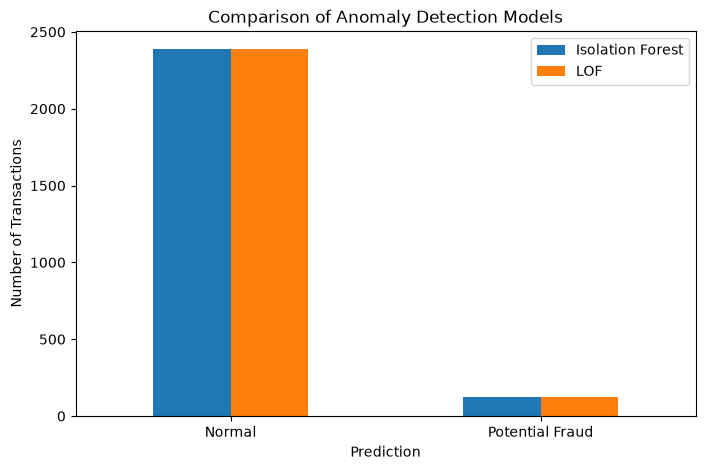

In [130]:
comparison = pd.DataFrame({
    'Isolation Forest': df_c['fraud_flag'].value_counts(),
    'LOF': df_c['lof_flag'].value_counts()
})

comparison.plot(kind='bar', figsize=(8,5))

plt.title('Comparison of Anomaly Detection Models')
plt.xlabel('Prediction')
plt.ylabel('Number of Transactions')
plt.xticks(rotation=0)

plt.show()

#### **Isolation Forest vs. LOF Agreement (Heatmap)**
#### **Findings:**
Both models agreed that 2,303 transactions were normal.
Both models agreed that 43 transactions were potential fraud.
Isolation Forest uniquely flagged 83 transactions that LOF classified as normal.
Likewise, LOF uniquely flagged 83 transactions that Isolation Forest classified as normal.
Overall, the models agreed on 2,346 out of 2,512 transactions (93.39%).

#### **Business Interpretation:**

The high agreement rate (93.39%) indicates that Isolation Forest and Local Outlier Factor generally identify similar transaction patterns. The 43 transactions flagged by both models represent the highest-confidence anomalies and should be prioritized for manual investigation, while the remaining disagreements highlight transactions that may require additional business rules or domain expertise to determine whether they are genuinely suspicious.

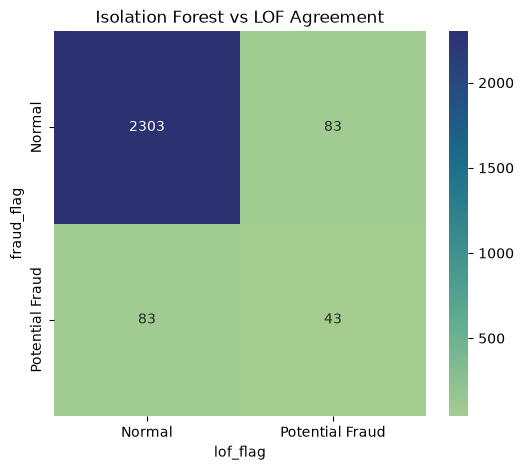

In [134]:
cross = pd.crosstab(
    df_c['fraud_flag'],
    df_c['lof_flag']
)

plt.figure(figsize=(6,5))

sns.heatmap(
    cross,
    annot=True,
    fmt='d',
    cmap='crest'
)

plt.title("Isolation Forest vs LOF Agreement")

plt.show()

### **Overall Model Comparison Findings:**

Isolation Forest and Local Outlier Factor produced highly consistent results, agreeing on 93.39% of all transactions. Both models identified 126 potential anomalies, with 43 transactions flagged by both algorithms. These jointly identified transactions represent the strongest candidates for further fraud investigation, while the remaining disagreements demonstrate that different anomaly detection techniques may capture different types of unusual behavior.

In [135]:
both = (
    (df_c['fraud_flag'] == 'Potential Fraud') &
    (df_c['lof_flag'] == 'Potential Fraud')
).sum()

iso_only = (
    (df_c['fraud_flag'] == 'Potential Fraud') &
    (df_c['lof_flag'] == 'Normal')
).sum()

lof_only = (
    (df_c['fraud_flag'] == 'Normal') &
    (df_c['lof_flag'] == 'Potential Fraud')
).sum()

summary = pd.DataFrame({
    'Category': [
        'Flagged by Both',
        'Isolation Only',
        'LOF Only'
    ],
    'Transactions': [
        both,
        iso_only,
        lof_only
    ]
})

summary

,Category,Transactions
0,Flagged by Both,43
1,Isolation Only,83
2,LOF Only,83


#### **Findings:**

- 43 transactions were flagged as anomalous by both Isolation Forest and Local Outlier Factor.
- 83 transactions were uniquely identified by Isolation Forest.
- 83 transactions were uniquely identified by Local Outlier Factor.

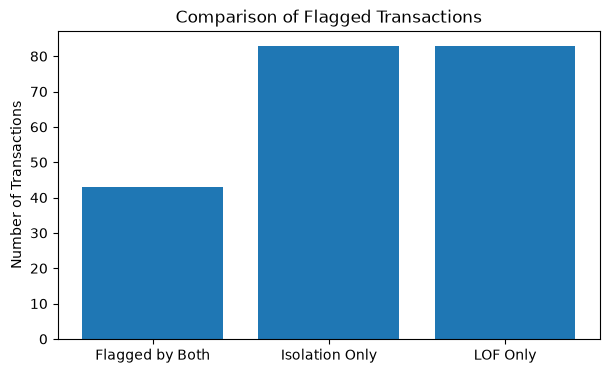

In [136]:
plt.figure(figsize=(7,4))

plt.bar(summary['Category'], summary['Transactions'])

plt.title('Comparison of Flagged Transactions')
plt.ylabel('Number of Transactions')

plt.show()

# **Conclusion**

This project aimed to identify anomalous banking transactions by analyzing transaction behavior, customer behavior, security behavior, and behavioral patterns through exploratory data analysis (EDA). The dataset contained no missing values or duplicate records, allowing the analysis to proceed with feature engineering and data preprocessing after appropriate data type conversions.

Two unsupervised machine learning algorithms, Isolation Forest and Local Outlier Factor (LOF), were implemented for anomaly detection. Both models were trained using the preprocessed dataset with a contamination rate of 5%. Isolation Forest was configured with 100 estimators, while Local Outlier Factor used 20 nearest neighbors. The models demonstrated an overall agreement rate of 93.39% when classifying transactions as normal or potential anomalies.

A comparison of the anomaly detection results showed that 43 transactions were flagged by both models, while 83 transactions were uniquely identified by Isolation Forest and another 83 transactions were uniquely identified by Local Outlier Factor. The presence of model-specific anomalies indicates that each algorithm captures different aspects of unusual transaction behavior in addition to their shared detections.

Transactions identified by both models represent the highest-confidence anomalies because they were independently detected by two different anomaly detection techniques. These transactions should be prioritized for manual review or further fraud investigation. Meanwhile, transactions uniquely flagged by either Isolation Forest or Local Outlier Factor may reflect different types of anomalous behavior, demonstrating that combining multiple anomaly detection algorithms provides broader coverage than relying on a single model alone.